# Evaluating Natural Language Explanations of Food Recommendation System XFoodRec Across Several LLMs

Authors: Junxuan Ling, Tianyi Liu, Anqi Zhou

# 0. Document Instructions

## 0.1. Git Version Control

After making modifications, please use Colab's function of "Save in Github to keep changes" (Github authorization required) to commit the changes to the repository (Your own branch if needed).

**NOTE**: When A modifies this notebook, but have not commited to Github, if B opens this notebook, they will see the Github old version.

## 0.2. Handle persistent data storage

Mount Google Drive instead of relying on Colab's temporary run-time storage.

**IMPORTANT:** Although Google Colab allows collaboration of the notebook, data and folders are originally in Junxuan's drive, this could cause issues when refering to the mounted directory path. To allow the code to work for all of us, (who's not junxuan) please create a **short-cut** of Junxuan's shared folder in our own Google Drive, path `MyDrive/`.

In [1]:
# load from drive
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 0.3 Setup and data loading

Run the notebook from top to bottom after Step 1 has saved the processed files. The sequence is: **load data → build matching resources → parse explanations → extract three claim types → combine claims → verify in 2.2**.

Function-definition cells prepare tools; cells labelled **Build**, **Prepare** or **Extract** apply them; **Inspect** cells summarize the results. Changing an upstream rule requires rerunning its dependent cells.

In [2]:
%pip install -q spacy pyarrow
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 51.3 MB/s eta 0:00:0000:0100:01
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [3]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import spacy

project_dir = Path("/content/drive/MyDrive/XFoodRec_Project_Data")
data_dir = project_dir / "raw"
processed_dir = project_dir / "processed"
persona_path = data_dir / "personas.json"
recommendation_path = data_dir / "recommendations.json"
recipe_path = data_dir / "recipes.parquet"
nutrition_fields_path = processed_dir / "nutrition_fields.json"

In [4]:
with persona_path.open("r", encoding="utf-8") as f:
    personas = json.load(f)
with recommendation_path.open("r", encoding="utf-8") as f:
    recommendations = json.load(f)

personas_df = pd.json_normalize(personas)
recipes = pd.read_parquet(recipe_path)
recipes["recipe_id"] = recipes["recipe_id"].astype(str)

In [5]:
explanation_lemmas_df = pd.read_parquet(processed_dir / "explanation_lemmas.parquet")
recipe_lemmas_df = pd.read_parquet(processed_dir / "recipe_lemmas.parquet")
persona_lemmas_df = pd.read_parquet(processed_dir / "persona_lemmas.parquet")
with nutrition_fields_path.open("r", encoding="utf-8") as f:
    nutrition_fields = json.load(f)

print("Explanations:", len(explanation_lemmas_df))
print("Source recipes:", len(recipes))
print("Personas:", len(personas_df))

Explanations: 536
Source recipes: 702
Personas: 40


# 2. Entity Extraction, Fact Verification & Hallucination Detection

## 2.0 Matching helpers reused from Step 1

In [6]:
import re

import spacy

MIN_PREFIX_LENGTH = 4  # word forms sharing a beginning match, e.g. "sugar" / "sugary"

text_nlp = spacy.load("en_core_web_sm", disable=["ner"])

# spaCy adds every processed string to its vocabulary, so keep the model's own word list as loaded.
SPACY_MODEL_WORDS = set(text_nlp.vocab.strings)
_base_forms = {}

In [7]:
def to_list(value):
    if isinstance(value, np.ndarray):
        value = value.tolist()
    return [str(v).lower() for v in value] if isinstance(value, (list, tuple)) else []


def base_forms(tokens):
    """spaCy lemma of each word on its own, so 'oats'/'oat' and 'potatoes'/'potato' align."""
    new = sorted({t for t in tokens if t not in _base_forms})
    for word, doc in zip(new, text_nlp.pipe(new)):
        _base_forms[word] = doc[0].lemma_.lower() if len(doc) else word
    return [_base_forms[t] for t in tokens]


def term_matches(token, term):
    shorter, longer = sorted((token, term), key=len)
    return token == term or (len(shorter) >= MIN_PREFIX_LENGTH and longer.startswith(shorter))


def contains_sequence(tokens, sequence):
    n = len(sequence)
    return n > 0 and any(tokens[i:i + n] == sequence for i in range(len(tokens) - n + 1))

In [8]:
def noun_phrase_core(chunk, is_name=False):
    """Main noun of a spaCy noun phrase with the words that name it: compounds and -ing words
    ('olive oil', 'baking mix'); describing words are dropped ('frozen vegetables' -> 'vegetable').
    For ingredient names (is_name=True) an -ing word right before the phrase also belongs to it."""
    root = chunk.root
    words = [t for t in chunk if t.i == root.i or (t.head.i == root.i and (t.dep_ == "compound" or t.tag_ == "VBG"))]
    before, after = chunk.start - 1, chunk.end
    if is_name and before >= 0 and chunk.doc[before].tag_ == "VBG" and chunk.doc[before] not in words:
        words = [chunk.doc[before]] + words
    if is_name and after < len(chunk.doc) and chunk.doc[after].tag_ == "VBG" and chunk.doc[after].head.i == root.i:
        words = words + [chunk.doc[after]]  # "salad dressing" when spaCy reads "dressing" as a verb
    terms = base_forms([t.text.lower() for t in words])
    return [] if all(t in text_nlp.Defaults.stop_words for t in terms) else terms


def clean_ingredient_line(line):
    """Drop notes in brackets, including a note that started on the previous line ('in this recipe)')."""
    line = str(line).lower()
    if ")" in line and ("(" not in line or line.index(")") < line.index("(")):
        line = line[line.index(")") + 1:]
    return re.sub(r"\([^)]*\)?", " ", line).strip()


def ingredient_line_names(doc):
    """Ingredient names in one parsed ingredient line: its main noun phrase and phrases joined to it by
    'and' / 'or'. A line that continues the previous one (starts with 'and' / 'or') gives nothing, and a
    'noun' that takes an object ('use salted butter') is read as a verb."""
    if len(doc) and doc[0].pos_ == "CCONJ":
        return []
    chunks = [c for c in doc.noun_chunks if not any(child.dep_ == "dobj" for child in c.root.children)]
    if not chunks:  # a bare name that spaCy does not parse as a noun phrase, e.g. "tahini"
        terms = base_forms([t.text.lower() for t in doc if not (t.is_punct or t.is_space or t.like_num)])
        return [terms] if terms and not all(t in text_nlp.Defaults.stop_words for t in terms) else []
    main = [c for c in chunks
            if c.root.dep_ == "ROOT" or (c.root.head.dep_ == "ROOT" and c.root.dep_ in ("dobj", "compound"))]
    main = main or chunks[:1]
    for c in chunks:
        if c not in main and c.root.dep_ == "conj" and any(c.root.head.i == m.root.i for m in main):
            main.append(c)
    return [name for name in (noun_phrase_core(c, is_name=True) for c in main) if name]

Assemble matching resources

In [9]:
persona_lemmas_df.head()

,document_id,recommendation_id,persona_id,recipe_id,rank,source_field,item_index,persona_text_lemmas
0,user_01:persona_description:0,None,user_01,None,None,persona_description,0,"[vegan, competitive, bodybuilder, focus, lean,..."
1,user_01:dietary_goal:0,None,user_01,None,None,dietary_goal,0,"[muscle, gain]"
2,user_01:dietary_restriction:0,None,user_01,None,None,dietary_restriction,0,[vegan]
3,user_01:dietary_restriction_other:0,None,user_01,None,None,dietary_restriction_other,0,"[high, protein, prefer, low, soy, option]"
4,user_01:liked_ingredient:0,None,user_01,None,None,liked_ingredient,0,[seitan]


In [10]:
recipe_lemmas_df.head()

,document_id,recommendation_id,persona_id,recipe_id,rank,source_field,item_index,recipe_text_lemmas
0,113861:recipe_title:0,None,None,113861,None,recipe_title,0,"[cube, steak, gravy]"
1,113861:recipe_ingredient:0,None,None,113861,None,recipe_ingredient,0,"[cub, steak]"
2,113861:recipe_ingredient:1,None,None,113861,None,recipe_ingredient,1,[oil]
3,113861:recipe_ingredient:2,None,None,113861,None,recipe_ingredient,2,[butter]
4,113861:recipe_ingredient:3,None,None,113861,None,recipe_ingredient,3,[flour]


In [11]:
recipes.head()

,recipe_id,title,recipe_url,image_url,ingredients,ingredients_title,tags,calories_per_serving [cal],calories_per_100g [cal],caloriesfromfat_per_serving [cal],...,dietaryfiber_per_serving [g],dietaryfiber_per_100g [g],sugars_per_serving [g],sugars_per_100g [g],protein_per_serving [g],protein_per_100g [g],who_score,fsa_score,nutri_score,health_score
0,113861,My Own Cube Steak and Gravy,https://www.food.com/recipe/my-own-cube-steak-...,https://img.sndimg.com/food/image/upload/f_aut...,"{'': [('cubed steak (4-6 pieces)', '2 time(s)...","[cubed steak (4-6 pieces), oil, butter, flour,...","[Moderate Calorie, Vegetarian]",500.5,175.6,216,...,0.8,0.3,0.8,0.3,48.0,16.8,0.266834,0.250,0.00,3.6
1,111212,Our Secret Sirloin Steak,https://www.food.com/recipe/our-secret-sirloin...,https://img.sndimg.com/food/image/upload/f_aut...,"{'': [('Lea & Perrins Worcestershire Sauce, pl...","[Lea & Perrins Worcestershire Sauce, Lea & Per...","[Moderate Calorie, Vegetarian]",823.6,320.5,502,...,0.4,0.2,3.4,1.3,69.5,27.0,0.186863,0.250,0.00,2.9
2,497021,Mile-High Cabbage Pie #5FIX,https://www.food.com/recipe/mile-high-cabbage-...,https://img.sndimg.com/food/image/upload/f_aut...,"{'': [('lean ground beef', '1 1/2 time(s) lbs ...","[lean beef, coleslaw mix (cabbage and carrots)...",[Moderate Calorie],803.0,221.2,298,...,7.0,1.9,10.7,2.9,48.7,13.4,0.266693,0.250,0.00,3.6
3,31184,15 Minute Shrimp Scampi,https://www.food.com/recipe/15-minute-shrimp-s...,https://img.sndimg.com/food/image/upload/f_aut...,"{'': [('extra virgin olive oil', '0.5 time(s) ...","[extra virgin olive oil, onion, cloves garlic,...",[Moderate Calorie],596.2,342.6,416,...,0.7,0.4,2.2,1.3,26.7,15.3,0.169814,0.250,0.00,2.7
4,71739,Easy Garlic Rice,https://www.food.com/recipe/easy-garlic-rice-7...,https://img.sndimg.com/food/image/upload/f_aut...,"{'': [('olive oil', '2 time(s) tablespoons ')...","[olive oil, onion, garlic cloves, long grain r...",[Moderate Calorie],264.2,190.1,70,...,1.3,0.9,1.6,1.2,6.3,4.5,0.222165,0.625,0.25,5.2


Tell foods apart with WordNet (liked ingredients)

In [12]:
from functools import lru_cache

import nltk
from nltk.corpus import wordnet as wn

try:
    wn.ensure_loaded()
except LookupError:
    nltk.download("wordnet", quiet=True)
    wn.ensure_loaded()


# WordNet's two general food senses; a sense below either of them names a food.
FOOD_SYNSETS = {wn.synset("food.n.01"), wn.synset("food.n.02")}


@lru_cache(maxsize=None)
def food_senses(words):
    """Return the WordNet noun senses in which *words* names a food."""
    senses = wn.synsets("_".join(words), pos=wn.NOUN)
    return tuple(
        sense for sense in senses
        if sense in FOOD_SYNSETS or FOOD_SYNSETS & set(sense.closure(lambda s: s.hypernyms()))
    )


def food_name(words):
    """Return the longest ending of *words* that WordNet recognizes as food."""
    for start in range(len(words)):
        if food_senses(tuple(words[start:])):
            return list(words[start:])
    return None


def different_foods(first, second):
    """Whether WordNet knows both phrases as unrelated foods."""
    first_senses = food_senses(tuple(first))
    second_senses = food_senses(tuple(second))
    if not first_senses or not second_senses:
        return False
    for first_sense in first_senses:
        for second_sense in second_senses:
            if (
                first_sense == second_sense
                or second_sense in set(first_sense.closure(lambda s: s.hypernyms()))
                or first_sense in set(second_sense.closure(lambda s: s.hypernyms()))
            ):
                return False
    return True


def liked_food_name(lemmas, core):
    """Return the user's complete food name up to the liked item's core noun."""
    words = base_forms(lemmas)
    if not core or core[-1] not in words:
        return None
    end = len(words) - words[::-1].index(core[-1])
    return food_name(words[:end])


def liked_food_here(terms, end, value, user_food):
    """Check that a matched liked-item core does not name a different food here."""
    here = food_name(terms[max(0, end - 3):end]) or value
    return user_food is None or not different_foods(here, user_food)


def item_key(lemmas):
    # this works (keep only the first noun) because for records under type `liked_ingredients`,
    # one record corresponds to only 1 ingredient.
    """Core noun phrase of a persona item: 'oats certify gf' -> 'oat', 'frozen vegetable' -> 'vegetable'."""
    doc = text_nlp(" ".join(lemmas))
    chunks = list(doc.noun_chunks)
    if not chunks:
        return base_forms(lemmas)
    root = chunks[0].root
    words = [t.text for t in chunks[0] if t.i == root.i or (t.dep_ == "compound" and t.head.i == root.i)]
    return base_forms(words)


def nutrient_terms_from_data(recipe_columns, nutrition_fields):
    """Nutrients recorded in the data: the recipe nutrient columns ('dietaryfiber_per_serving [g]'
    -> 'fiber') and nutrition_fields.json. Compound column names keep their longest ending that is
    an English word in spaCy's vocabulary."""
    terms = {str(f).lower() for f in nutrition_fields}
    for column in recipe_columns:
        name = re.sub(r"\[[^\]]*\]", "", str(column).lower()).strip()
        if "_per_" not in name:
            continue
        word = name.split("_per_")[0]
        endings = [word[i:] for i in range(len(word)) if word[i:] in SPACY_MODEL_WORDS]
        terms.add(max(endings, key=len) if endings else word)
    return sorted(set(base_forms(sorted(terms))))


def build_persona_values(persona_lemmas_df):
    # Persona fields: the taste profile and the dietary needs.
    TASTE_FIELDS = [
        "liked_ingredient",
        "disliked_ingredient",
        "favorite_cuisine",
    ]
    HEALTH_FIELDS = [
        "dietary_goal",
        "dietary_restriction",
        "food_allergy",
        "health_condition",
    ]

    # Liked ingredients keep only their core noun phrase ("frozen vegetables" -> "vegetable").
    # Disliked ingredients keep their full phrase, because the describing word is often
    # what the user dislikes ("spicy foods", "complicated recipes").
    NOUN_PHRASE_FIELDS = [
        "liked_ingredient",
    ]

    # Allergens are foods ("egg", "milk"), so they are not general health labels.
    NOT_A_LABEL_FIELDS = ["food_allergy"]

    # persona_id: [(source_field, term)]
    persona_values = {}

    # (persona_id, liked item core) -> the user's food as WordNet names it
    liked_food_names = {}

    for row in persona_lemmas_df.to_dict("records"):
        # Only personal taste and dietary information are relevant.
        field = row["source_field"]

        if field not in TASTE_FIELDS + HEALTH_FIELDS:
            continue

        lemmas = to_list(row["persona_text_lemmas"])
        terms = (
            item_key(lemmas)
            if field in NOUN_PHRASE_FIELDS
            else base_forms(lemmas)
        )

        if terms:
            persona_values.setdefault(
                str(row["persona_id"]),
                [],
            ).append((field, terms))  # source field -> term

            # keep the user's food, so a shortened liked item is not matched to a different food
            if field == "liked_ingredient":
                liked_food_names[(str(row["persona_id"]), tuple(terms))] = liked_food_name(lemmas, terms)

    # get taste terms
    taste_values = {
        tuple(terms)
        for values in persona_values.values()
        for field, terms in values
        if field in TASTE_FIELDS
    }

    # health labels
    health_label_values = sorted({
        tuple(terms)  # keep terms
        for values in persona_values.values()
        for field, terms in values
        if (
            # is health not allergy
            field in HEALTH_FIELDS
            and field not in NOT_A_LABEL_FIELDS
            and tuple(terms) not in taste_values
        )
    })

    return persona_values, health_label_values, liked_food_names


def build_recipe_titles(recipe_lemmas_df):
    # id: title [lemmas]
    return {
        str(row["recipe_id"]): base_forms(
            to_list(row["recipe_text_lemmas"])
        )
        for row in recipe_lemmas_df.to_dict("records")
        if row["source_field"] == "recipe_title"
    }


def build_ingredient_names(recipe_table):
    # recipe -> ingredients
    line_recipes = []
    line_texts = []

    for recipe_id, lines in zip(
        recipe_table["recipe_id"].astype(str),
        recipe_table["ingredients_title"],
    ):
        for line in to_list(lines):
            line_recipes.append(recipe_id)
            # drop note in brackets and append
            line_texts.append(clean_ingredient_line(line))

    # recipe_id: {(ingredient), (ingredient)}
    ingredient_names = {}

    for recipe_id, doc in zip(
        line_recipes,
        # spaCy tokenize and POS, output doc
        text_nlp.pipe(line_texts, batch_size=256),
    ):
        # all the ingredients retrieved
        for name in ingredient_line_names(doc):
            ingredient_names.setdefault(
                recipe_id,
                set(),
            ).add(tuple(name))

    # construct food term set based on recipe ingredients
    food_terms = set().union(*ingredient_names.values())

    return ingredient_names, food_terms


def build_matching_resources(
    persona_lemmas_df,
    recipe_lemmas_df,
    recipe_table,
    nutrition_fields,
):
    persona_values, health_label_values, liked_food_names = build_persona_values(
        persona_lemmas_df
    )

    titles = build_recipe_titles(recipe_lemmas_df)

    ingredient_names, food_terms = build_ingredient_names(
        recipe_table
    )

    return {
        # persona_id: mentioned terms from different sources
        "persona_values": persona_values,

        # (persona_id, liked item core) -> the user's food as WordNet names it
        "liked_food_names": liked_food_names,

        # health related choices (e.g. diet)
        "health_label_values": [
            list(value)
            for value in health_label_values
        ],

        # recipe_id -> recipe_title
        "titles": titles,

        # all the nutrients ["calorie", "fat", ...]
        "nutrient_terms": nutrient_terms_from_data(
            list(recipe_table.columns),
            nutrition_fields,
        ),

        # recipe_id -> ingredients
        "ingredient_names": ingredient_names,

        # all the ingredients the recipe mentioned
        "food_terms": food_terms,
    }

In [13]:
# preprocess the former lemma dfs, for future analysis

recipe_table = recipes
matching_resources = build_matching_resources(persona_lemmas_df, recipe_lemmas_df, recipe_table, nutrition_fields)

print(
    "Nutrients:",
    matching_resources["nutrient_terms"][:10],
)

print(
    "Health labels:",
    matching_resources["health_label_values"][:10],
)

print(
    "Persona examples:",
    list(matching_resources["persona_values"].items())[:3],
)

print(
    "Recipe ingredient examples:",
    list(matching_resources["ingredient_names"].items())[:3],
)

print(
    "Food terms:",
    list(matching_resources["food_terms"])[:10],
)

Nutrients: ['calorie', 'carb', 'carbohydrate', 'cholesterol', 'fat', 'fiber', 'protein', 'sodium', 'sugar']
Health labels: [['adhd'], ['anemia'], ['anti', 'inflammatory'], ['arfid'], ['asthma'], ['autism', 'spectrum'], ['celiac', 'disease'], ['copd'], ['dairy', 'free'], ['diabete', 'type-1']]
Persona examples: [('user_01', [('dietary_goal', ['muscle', 'gain']), ('dietary_restriction', ['vegan']), ('liked_ingredient', ['seitan']), ('liked_ingredient', ['lentil']), ('liked_ingredient', ['chickpea']), ('liked_ingredient', ['hemp', 'seed']), ('disliked_ingredient', ['mushroom']), ('disliked_ingredient', ['eggplant']), ('favorite_cuisine', ['middle', 'eastern']), ('favorite_cuisine', ['indian']), ('favorite_cuisine', ['mediterranean'])]), ('user_02', [('dietary_goal', ['medical', 'management']), ('dietary_restriction', ['low', 'carb']), ('food_allergy', ['tree', 'nut']), ('health_condition', ['diabete', 'type-1']), ('liked_ingredient', ['chicken']), ('liked_ingredient', ['greek', 'yogurt'])

## 2.1. Extract three types of claims


Prepare original explanations (preprocess)

In [14]:
recommendations[0]

{'persona': {'id': 'user_01',
  'description': 'A vegan competitive bodybuilder focused on lean bulking without soy overload.',
  'profile': {'age': 28,
   'gender': 'Male',
   'height': 182.0,
   'weight': 84.0,
   'activityLevel': 'very_active',
   'dietary_goal': 'Muscle Gain',
   'dietaryProfile': {'dietaryRestrictions': {'selected': ['Vegan'],
     'other': 'High-protein, prefers low-soy options'},
    'foodAllergies': {'selected': [], 'other': ''},
    'healthConditions': {'selected': [], 'other': ''}},
   'likedIngredients': ['Seitan', 'Lentils', 'Chickpeas', 'Hemp seeds'],
   'dislikedIngredients': ['Mushrooms', 'Eggplant'],
   'favoriteCuisines': ['Middle Eastern', 'Indian', 'Mediterranean']}},
 'recommendations': [{'recipe_id': '81968',
   'title': 'Chickpeas With Spinach (Greek)',
   'explanation': 'Chickpeas With Spinach (Greek) is a fantastic choice packed with protein, aligning perfectly with your muscle gain goal. The inclusion of chickpeas and spinach not only satisfies

In [15]:
explanation_lemmas_df.head()

,document_id,recommendation_id,persona_id,recipe_id,rank,source_field,item_index,explanation_lemmas
0,user_01_rank_01:explanation:0,user_01_rank_01,user_01,81968,1,explanation,0,"[chickpea, spinach, greek, fantastic, choice, ..."
1,user_01_rank_02:explanation:0,user_01_rank_02,user_01,10614,2,explanation,0,"[refried, beans, offer, high, protein, content..."
2,user_01_rank_03:explanation:0,user_01_rank_03,user_01,94673,3,explanation,0,"[egyptian, red, lentil, soup, rich, protein, f..."
3,user_01_rank_04:explanation:0,user_01_rank_04,user_01,364252,4,explanation,0,"[favorite, sauteed, kale, nutrient, dense, opt..."
4,user_01_rank_05:explanation:0,user_01_rank_05,user_01,12569,5,explanation,0,"[hearty, black, beans, rice, combine, protein,..."


In [16]:
# Parse every explanation once; 2.1 a-c read their claims from these parses.

# Same ids as the processed lemma table: "<persona id>_rank_<rank>".
# user_01_rank_01 -> explanation text
claim_texts = {
    f"{entry['persona']['id']}_rank_{rank:02d}": rec["explanation"]
    for entry in recommendations
    for rank, rec in enumerate(entry["recommendations"], start=1)
}
print(claim_texts)
print(len(claim_texts)==len(explanation_lemmas_df))

claim_index = explanation_lemmas_df[["recommendation_id", "persona_id", "recipe_id", "rank"]].copy()
claim_ids = claim_index["recommendation_id"].tolist()

claim_docs = dict(
    zip(
        claim_ids,
        text_nlp.pipe([
            claim_texts[i]
            for i in claim_ids
        ], batch_size=64) # nlp process for all explanations, return doc.
    )
)

{'user_01_rank_01': 'Chickpeas With Spinach (Greek) is a fantastic choice packed with protein, aligning perfectly with your muscle gain goal. The inclusion of chickpeas and spinach not only satisfies your taste for legumes but also provides essential nutrients for recovery and growth.', 'user_01_rank_02': 'Refried Beans offers a high protein content, making it a great option for muscle gain. The use of black beans ensures a hearty meal that aligns with your preferences, while being low in fat.', 'user_01_rank_03': 'Egyptian Red Lentil Soup is rich in protein and fiber, ideal for your muscle gain goal. It features lentils, which you enjoy, and provides a warming, nutritious meal that can support your active lifestyle.', 'user_01_rank_04': 'My Favorite Sauteed Kale is a nutrient-dense option that complements your diet with vitamins and minerals while being low in calories. The olive oil adds healthy fats, making it a balanced side dish for muscle gain.', 'user_01_rank_05': 'Hearty Black 

Locate recipe titles and skip title in later analysis

In [17]:
title_by_recipe = dict(
    zip(
        recipe_table["recipe_id"].astype(str),
        recipe_table["title"].astype(str).str.lower(),
    ) # recipe -> title
)

claim_title_spans = {}

for row in claim_index.itertuples():
    recommendation_id = row.recommendation_id
    explanation = claim_texts[recommendation_id].lower()

    title = title_by_recipe.get(str(row.recipe_id), "")

    # find where the title locates in explanation
    title_spans = [
        (match.start(), match.end())
        for match in re.finditer(re.escape(title), explanation)
    ]

    claim_title_spans[recommendation_id] = title_spans

# claim_title_spans

In [18]:
print("Explanations parsed:", len(claim_docs))
print("Explanations whose text contains the recipe title:", sum(bool(s) for s in claim_title_spans.values()))

Explanations parsed: 536
Explanations whose text contains the recipe title: 503


helpers

In [19]:
# avoid treat recipe title as ingredient claim, whether the text is outside title
def outside_title(span, recommendation_id):
    return not any(span.start_char < end and span.end_char > start for start, end in claim_title_spans[recommendation_id])

# which sentence is the text span located
def sentence_number(span):
    return next(k for k, sentence in enumerate(span.doc.sents) if sentence.start <= span.start < sentence.end)

# if the word have not/never before.
def is_negated(token):
    """spaCy's negation mark ('not', 'never') on the word or the words it hangs from, up to its verb,
    or the word being the object of 'without' ('without added sugars'). A 'not' with words of its own
    ('not only ... but also') does not negate."""
    chain = [token]
    while chain[-1].pos_ not in ("VERB", "AUX") and chain[-1].head.i != chain[-1].i:
        chain.append(chain[-1].head)
    return (any(child.dep_ == "neg" and not list(child.children) for t in chain for child in t.children)
            or any(t.dep_ == "prep" and t.lower_ == "without" for t in chain))

### a. Ingredient mentions

collect ingredient claims (match food term)

In [20]:
import nltk
from nltk.corpus import wordnet as wn

# Run once if WordNet is not installed.
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [21]:
# deleted wordnet synset because of false matches.

# Use food terms found in the recipe corpus.
food_terms = matching_resources["food_terms"]

ingredient_claim_rows = []

for recommendation_id, doc in claim_docs.items():
    for chunk in doc.noun_chunks:
        # Ignore the recipe title.
        if not outside_title(chunk, recommendation_id):
            continue

        # Skip generic phrases such as "a mix of flavors".
        has_of_phrase = any(
            child.dep_ == "prep" and child.lower_ == "of"
            for child in chunk.root.children
        )
        if has_of_phrase:
            continue

        # Extract the full food name and its root noun.
        core = noun_phrase_core(chunk)
        root = base_forms([chunk.root.text.lower()])

        # Try the full name first, then the root noun.
        if tuple(core) in food_terms:
            term = core
        elif (
            root
            and tuple(root) in food_terms
            and root[0] not in text_nlp.Defaults.stop_words
        ):
            term = root
        else:
            continue

        # Store the matched food term.
        ingredient_claim_rows.append({
            "recommendation_id": recommendation_id,
            "claim_type": "ingredient",
            "sentence": sentence_number(chunk),
            "text": chunk.text,
            "term": " ".join(term),
            "negated": is_negated(chunk.root),
            "start_char": chunk.start_char,
            "end_char": chunk.end_char,
        })

ingredient_claims_df = pd.DataFrame(ingredient_claim_rows)

In [22]:
# Count ingredient mentions in each explanation.
mentions_per_explanation = (
    ingredient_claims_df
    .groupby("recommendation_id")
    .size()
    .reindex(claim_index["recommendation_id"], fill_value=0)
)

total_mentions = len(ingredient_claims_df)
total_explanations = len(mentions_per_explanation)
explanations_with_mentions = (mentions_per_explanation > 0).sum()
coverage_percentage = 100 * (mentions_per_explanation > 0).mean()

print(
    f"Ingredient mentions: {total_mentions} in "
    f"{explanations_with_mentions} of {total_explanations} explanations "
    f"({coverage_percentage:.1f}%)"
)

# Show the distribution of ingredient mentions per explanation.
mention_distribution = (
    mentions_per_explanation
    .value_counts()
    .sort_index()
    .rename_axis("mentions in one explanation")
    .rename("explanations")
    .to_frame()
)

display(mention_distribution)

# Rank ingredients by their total mentions.
top_ingredients = (
    ingredient_claims_df
    .groupby("term")
    .agg(
        mentions=("recommendation_id", "size"),
        explanations=("recommendation_id", "nunique"),
    )
    .sort_values("mentions", ascending=False)
)

display(top_ingredients.head(15))

Ingredient mentions: 504 in 333 of 536 explanations (62.1%)


,explanations
mentions in one explanation,
0,203
1,188
2,123
3,19
4,2
5,1


,mentions,explanations
term,,
chicken,96,94
vegetable,63,63
rice,46,45
bean,28,26
banana,19,19
egg,16,16
spinach,15,13
salmon,15,14
chicken breast,11,11


### b. Nutrient claims

Each claim keeps what the sentence says about it:

| Column | What it holds | Example |
|---|---|---|
| `number`, `unit` | An amount given for the nutrient | "33.1g of protein" → 33.1, g; "161 calories" → 161, calorie; "low in calories at 159.6" → 159.6 |
| `qualifier` | The describing word tied to the nutrient in the sentence | "high in protein" → high; "a good source of fiber" → good; "low-calorie" → low; "protein-packed" → packed |

A nutrient word with neither ("combines protein and fiber") is a plain mention. Nutrients joined by "and" share their wording: in "rich in protein and fiber" both are "rich". A number that the sentence structure does not tie to a nutrient belongs to the closest nutrient before it in the same sentence, if that nutrient has no number yet.

Nutrient words said about the user rather than the dish, i.e. in a phrase owned by "your" ("your low-carb diet", "your favorite proteins", "complements your protein-rich meals"), are not nutrient claims. When such a phrase names a user label ("low carb", "high protein") it is a label claim in c.

In [23]:
nutrient_terms = matching_resources["nutrient_terms"]


def nutrient_name(word):
    """Return the canonical nutrient name for a word, or None."""
    base_form = base_forms([word.lower()])[0]

    matching_names = [
        nutrient
        for nutrient in nutrient_terms
        if term_matches(base_form, nutrient)
    ]

    if base_form in matching_names:
        return base_form

    return next(iter(matching_names), None)


def about_user(token):
    """Check whether a phrase refers to something belonging to the user."""
    current_token = token

    while True:
        has_second_person_possessive = any(
            child.dep_ == "poss"
            and "2" in child.morph.get("Person")
            for child in current_token.children
        )

        if has_second_person_possessive:
            return True

        reached_root = current_token.head.i == current_token.i
        reached_verb = current_token.pos_ in ("VERB", "AUX")

        if reached_root or reached_verb:
            return False

        current_token = current_token.head

In [24]:
def is_describing(token):
    """An adjective or past participle: 'high', 'lower', 'rich', 'packed'."""
    return token.tag_ in ("JJ", "JJR", "JJS", "VBN")


def is_amount(token):
    return bool(re.fullmatch(r"\d[\d,]*(\.\d+)?", token.text))


def words_in_front(noun):
    """Describing words placed before a noun: 'low' in 'low-calorie', 'good' in 'a good source'."""
    return [c for c in noun.children if c.dep_ == "amod" and c.i < noun.i and is_describing(c)]


def describing_word_of(prep):
    """The describing word a phrase like 'in calories' belongs to ('high in protein', 'packed with protein'):
    the closest one before it, also when spaCy hangs the phrase on the verb ('is low | in calories')."""
    governor = prep.head
    candidates = [governor] if is_describing(governor) else []
    candidates += [c for c in governor.children if c.dep_ in ("acomp", "attr", "conj") and is_describing(c)]
    return sorted((c for c in candidates if c.i < prep.i), key=lambda c: c.i)[-1:]

In [25]:
def read_nutrient_claim(token):
    """Extract qualifiers, amount, and unit for a nutrient token."""
    qualifier = words_in_front(token)
    number = None
    unit = None

    # Handle amounts such as "161 calories" and "25g protein".
    amounts = [
        child
        for child in token.children
        if (
            child.dep_ == "nummod" # number and describes the token
            and child.i < token.i
            and is_amount(child)
        )
    ]

    if amounts:
        number = amounts[0]

        units = [
            child
            for child in token.children
            if (
                child.dep_ == "compound"
                and number.i < child.i < token.i
            )
        ]

        unit = units[0] if units else token

    # Share wording between joined nutrients:
    # "rich in protein and fiber".
    anchor = token

    while (
        anchor.dep_ == "conj"
        and anchor.head.is_alpha
        and nutrient_name(anchor.head.text)
    ):
        anchor = anchor.head

    # Handle shared qualifiers: "lower calories and fat".
    if anchor is not token and not qualifier:
        qualifier = words_in_front(anchor)

    holder = anchor.head

    if anchor.dep_ == "pobj" and holder.dep_ == "prep":
        qualifier += describing_word_of(holder)
        noun = holder.head

        # Handle "a good source of protein" and "21.4g of protein".
        if holder.lower_ == "of" and noun.pos_ in ("NOUN", "PROPN"):
            if not qualifier:
                qualifier += words_in_front(noun)

            counts = [
                child
                for child in noun.children
                if child.dep_ == "nummod" and is_amount(child)
            ]

            if counts and number is None and anchor is token:
                number = counts[0]
                unit = noun

    elif (
        anchor.dep_ in ("compound", "amod", "nmod", "npadvmod")
        and holder.i != anchor.i
    ):
        # Handle "protein-rich" and "protein-packed".
        if is_describing(holder):
            qualifier.append(holder)

        # Handle "high protein content" and "moderate calorie option".
        elif not qualifier:
            qualifier += [
                word
                for word in words_in_front(holder)
                if word.i < anchor.i
            ]

    # Handle phrases such as "keeping `calories` low".
    elif anchor.dep_ == "dobj":
        qualifier += [
            child
            for child in holder.children
            if child.dep_ == "oprd" and is_describing(child)
        ]

    return qualifier, number, unit

In [26]:
nutrient_claim_rows = []

for recommendation_id, doc in claim_docs.items():
    claims = []

    # Find nutrient terms in the explanation.
    for token in doc:
        if not token.is_alpha:
            continue

        nutrient = nutrient_name(token.text) # yes or no
        token_span = doc[token.i : token.i + 1]

        if (
            not nutrient
            or not outside_title(token_span, recommendation_id) # is in title
            or about_user(token) # is this about persona? e.g. your low-carb diet
        ):
            continue

        qualifier, number, unit = read_nutrient_claim(token)

        claims.append({
            "token": token,
            "term": nutrient,
            "qualifier": qualifier,
            "number": number,
            "unit": unit,
        })

    # Track amounts connected to a nutrient.
    used_amounts = {
        claim["number"].i
        for claim in claims
        if claim["number"] is not None
    }

    # Assign an unconnected amount to the closest preceding nutrient
    # in the same sentence.
    for amount in doc:
        amount_span = doc[amount.i : amount.i + 1]

        # find other numbers
        if (
            not is_amount(amount)
            or amount.i in used_amounts
            or not outside_title(amount_span, recommendation_id)
        ):
            continue

        preceding_claims = [
            claim
            for claim in claims
            if (
                claim["token"].i < amount.i
                and claim["token"].sent.start == amount.sent.start
            )
        ]

        if preceding_claims and preceding_claims[-1]["number"] is None: # find the nutrient term before this number
            closest_claim = preceding_claims[-1]
            closest_claim["number"] = amount
            closest_claim["unit"] = (
                amount.head if amount.dep_ == "nummod" else None
            )

    # Convert extracted claims into table rows.
    for claim in claims:
        claim_words = (
            [claim["token"]]
            + claim["qualifier"]
            + [
                word
                for word in (claim["number"], claim["unit"])
                if word is not None
            ]
        )

        start = min(word.i for word in claim_words)
        end = max(word.i for word in claim_words) + 1
        span = doc[start:end]

        sorted_qualifiers = sorted(
            set(claim["qualifier"]),
            key=lambda word: word.i,
        )
        qualifier_text = (
            " ".join(word.lower_ for word in sorted_qualifiers) or None
        )

        number_value = (
            float(claim["number"].text.replace(",", ""))
            if claim["number"] is not None
            else None
        )

        unit_name = (
            base_forms([claim["unit"].lower_.rstrip(".")])[0]
            if claim["unit"] is not None
            else None
        )

        nutrient_claim_rows.append({
            "recommendation_id": recommendation_id,
            "claim_type": "nutrient",
            "sentence": sentence_number(span),
            "text": span.text,
            "term": claim["term"],
            "qualifier": qualifier_text,
            "number": number_value,
            "unit": unit_name,
            "negated": is_negated(claim["token"]),
            "start_char": span.start_char,
            "end_char": span.end_char,
        })

nutrient_claims_df = pd.DataFrame(nutrient_claim_rows)

nutrient_claims_df.head()

,recommendation_id,claim_type,sentence,text,term,qualifier,number,unit,negated,start_char,end_char
0,user_01_rank_01,nutrient,0,packed with protein,protein,packed,NaN,None,False,53,72
1,user_01_rank_02,nutrient,0,high protein,protein,high,NaN,None,False,23,35
2,user_01_rank_02,nutrient,1,low in fat,fat,low,NaN,None,False,179,189
3,user_01_rank_03,nutrient,0,rich in protein,protein,rich,NaN,None,False,28,43
4,user_01_rank_03,nutrient,0,rich in protein and fiber,fiber,rich,NaN,None,False,28,53


In [27]:
# Count nutrient claims in each explanation.
claims_per_explanation = (
    nutrient_claims_df
    .groupby("recommendation_id")
    .size()
    .reindex(claim_index["recommendation_id"], fill_value=0)
)

total_claims = len(nutrient_claims_df)
total_explanations = len(claims_per_explanation)
explanations_with_claims = (claims_per_explanation > 0).sum()
coverage_percentage = 100 * (claims_per_explanation > 0).mean()

print(
    f"Nutrient claims: {total_claims} in "
    f"{explanations_with_claims} of {total_explanations} explanations "
    f"({coverage_percentage:.1f}%)"
)

# Classify nutrient claims by form.
has_number = nutrient_claims_df["number"].notna()
has_qualifier = nutrient_claims_df["qualifier"].notna()

nutrient_forms = pd.DataFrame(
    {
        "claims": [
            has_number.sum(),
            (~has_number & has_qualifier).sum(),
            (~has_number & ~has_qualifier).sum(),
            nutrient_claims_df["negated"].sum(),
        ]
    },
    index=[
        "with a number",
        "with a describing word only",
        "plain mention",
        "negated (any of the above)",
    ],
)

display(nutrient_forms)

# Summarize claims by nutrient.
nutrient_summary = (
    nutrient_claims_df
    .groupby("term")
    .agg(
        claims=("recommendation_id", "size"),
        explanations=("recommendation_id", "nunique"),
        with_number=("number", "count"),
        with_describing_word=("qualifier", "count"),
    )
    .sort_values("claims", ascending=False)
)

display(nutrient_summary)

# Show the most common describing words.
top_qualifiers = (
    nutrient_claims_df["qualifier"]
    .value_counts()
    .head(15)
    .rename_axis("describing word")
    .rename("claims")
    .to_frame()
)

display(top_qualifiers)

Nutrient claims: 795 in 494 of 536 explanations (92.2%)


,claims
with a number,159
with a describing word only,581
plain mention,55
negated (any of the above),8


,claims,explanations,with_number,with_describing_word
term,,,,
protein,303,291,64,232
calorie,294,274,86,218
carbohydrate,65,65,8,51
fat,45,45,0,43
fiber,43,43,0,35
carb,34,33,1,25
sodium,9,8,0,7
sugar,2,2,0,1


,claims
describing word,
low,130
good,119
rich,70
moderate,58
lower,58
higher,41
high,31
packed,20
healthy,15


### c. Diet / health-label claims

A label claim is a goal, diet or health condition from the user profiles (the health label values of the shared helpers) named in the explanation outside the recipe title, e.g. "your weight loss goal", "a vegetarian option", "your gluten-free needs". A longer form of a label word also counts ("ketogenic" for keto, "energy-boosting" for energy boost); a shorter one does not ("main" is not maintenance). When one label sits inside a longer one ("vegetarian" in "jain vegetarian"), only the longer one is kept.

A label that contains a nutrient word ("low carb", "high protein") counts here only when it is said about the user ("your low-carb diet"); said about the dish ("a high-protein dish") it is a nutrient claim in b. General wording that names no label ("fits your dietary restrictions", "free from allergens") is not a label claim.

In [28]:
matching_resources["health_label_values"][:10]

[['adhd'],
 ['anemia'],
 ['anti', 'inflammatory'],
 ['arfid'],
 ['asthma'],
 ['autism', 'spectrum'],
 ['celiac', 'disease'],
 ['copd'],
 ['dairy', 'free'],
 ['diabete', 'type-1']]

In [29]:
label_values = matching_resources["health_label_values"]

# Labels containing nutrient terms, such as "low carb".
# They count as health labels only when referring to the user.
nutrient_labels = {
    tuple(label)
    for label in label_values
    if any(nutrient_name(word) for word in label)
}


def extends(word, label_part):
    """Check whether a word exactly matches or extends a label term."""
    is_exact_match = word == label_part
    is_extended_form = (
        len(label_part) >= MIN_PREFIX_LENGTH
        and word.startswith(label_part)
    )

    return is_exact_match or is_extended_form

In [30]:
label_claim_rows = []

for recommendation_id, doc in claim_docs.items():
    # Ignore punctuation so "gluten-free" matches "gluten free".
    words = [
        token
        for token in doc
        if not (token.is_punct or token.is_space)
    ]
    base_words = base_forms([token.lower_ for token in words])

    matched_labels = []

    # Find every health label in the explanation.
    for label_value in label_values:
        label_length = len(label_value)

        for start_index in range(len(words) - label_length + 1):
            candidate_words = base_words[
                start_index : start_index + label_length
            ]

            is_match = all(
                extends(word, label_part)
                for word, label_part in zip(
                    candidate_words,
                    label_value,
                )
            )

            if is_match:
                first_token = words[start_index]
                last_token = words[start_index + label_length - 1]
                span = doc[first_token.i : last_token.i + 1]

                matched_labels.append((span, label_value))

    for span, label_value in matched_labels:
        # Skip labels contained within a longer matched label.
        is_part_of_longer_label = any(
            other_span.start <= span.start
            and span.end <= other_span.end
            and len(other_span) > len(span)
            for other_span, _ in matched_labels
        )

        if is_part_of_longer_label:
            continue

        # Ignore labels appearing in the recipe title.
        if not outside_title(span, recommendation_id):
            continue

        # Nutrient labels count only when they refer to the user.
        is_nutrient_label = tuple(label_value) in nutrient_labels

        if is_nutrient_label and not about_user(span.root):
            continue

        label_claim_rows.append({
            "recommendation_id": recommendation_id,
            "claim_type": "label",
            "sentence": sentence_number(span),
            "text": span.text,
            "term": " ".join(label_value),
            "negated": is_negated(span.root),
            "start_char": span.start_char,
            "end_char": span.end_char,
        })

label_claims_df = pd.DataFrame(label_claim_rows)

In [31]:
# Count label claims in each explanation.
labels_per_explanation = (
    label_claims_df
    .groupby("recommendation_id")
    .size()
    .reindex(claim_index["recommendation_id"], fill_value=0)
)

total_claims = len(label_claims_df)
total_explanations = len(labels_per_explanation)
explanations_with_claims = (labels_per_explanation > 0).sum()
coverage_percentage = 100 * (labels_per_explanation > 0).mean()
negated_claims = label_claims_df["negated"].sum()

print(
    f"Diet / health-label claims: {total_claims} in "
    f"{explanations_with_claims} of {total_explanations} explanations "
    f"({coverage_percentage:.1f}%), "
    f"negated: {negated_claims}"
)

# Summarize claims by health label.
label_summary = (
    label_claims_df
    .groupby("term")
    .agg(
        claims=("recommendation_id", "size"),
        explanations=("recommendation_id", "nunique"),
    )
    .sort_values("claims", ascending=False)
)

display(label_summary)

Diet / health-label claims: 252 in 231 of 536 explanations (43.1%), negated: 2


,claims,explanations
term,,
weight loss,52,52
muscle gain,45,45
vegetarian,35,35
energy boost,28,28
maintenance,25,25
medical management,13,13
vegan,11,11
high protein,8,8
anti inflammatory,7,7


### d. All claims

The three tables are stacked into `claims_df`, one row per claim, with the persona, recipe and rank of the explanation. Columns that do not apply to a claim type (`qualifier`, `number`, `unit` outside b) are empty.

----
Combine the three claim tables

Join the extracted rows to their persona, recipe and rank identifiers. `claims_df` is the main input for Step 2.2.

In [32]:
claim_tables = {
    "ingredient": ingredient_claims_df,
    "nutrient": nutrient_claims_df,
    "label": label_claims_df,
}

# Combine all claim types and add recommendation metadata.
claims_df = (
    pd.concat(
        claim_tables.values(),
        ignore_index=True,
    )
    .merge(
        claim_index,
        on="recommendation_id",
        how="left",
        validate="many_to_one",
    )
)

# Arrange columns in a consistent order.
claim_columns = [
    "recommendation_id",
    "persona_id",
    "recipe_id",
    "rank",
    "claim_type",
    "sentence",
    "text",
    "term",
    "qualifier",
    "number",
    "unit",
    "negated",
    "start_char",
    "end_char",
]

claims_df = claims_df[claim_columns]

In [33]:
explanation_count = len(claim_index)

# Summarize each claim type.
summary_rows = {}

for claim_type, table in claim_tables.items():
    summary_rows[claim_type] = {
        "claims": len(table),
        "negated": int(table["negated"].sum()),
        "explanations": table["recommendation_id"].nunique(),
    }

# Add totals across all claim types.
explanations_with_any_claim = claims_df["recommendation_id"].nunique()

summary_rows["any"] = {
    "claims": len(claims_df),
    "negated": int(claims_df["negated"].sum()),
    "explanations": explanations_with_any_claim,
}

claim_summary = pd.DataFrame.from_dict(
    summary_rows,
    orient="index",
)

claim_summary["percent of explanations"] = (
    100 * claim_summary["explanations"] / explanation_count
).round(1)

display(claim_summary)

explanations_without_claims = (
    explanation_count - explanations_with_any_claim
)

print(
    "Explanations without any claim:",
    explanations_without_claims,
)

,claims,negated,explanations,percent of explanations
ingredient,504,1,333,62.1
nutrient,795,8,494,92.2
label,252,2,231,43.1
any,1551,11,527,98.3


Explanations without any claim: 9


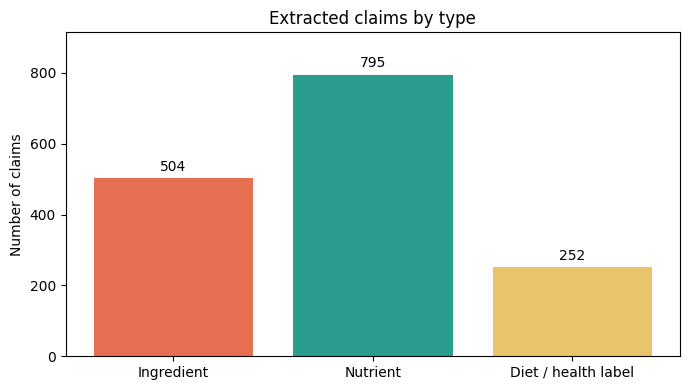

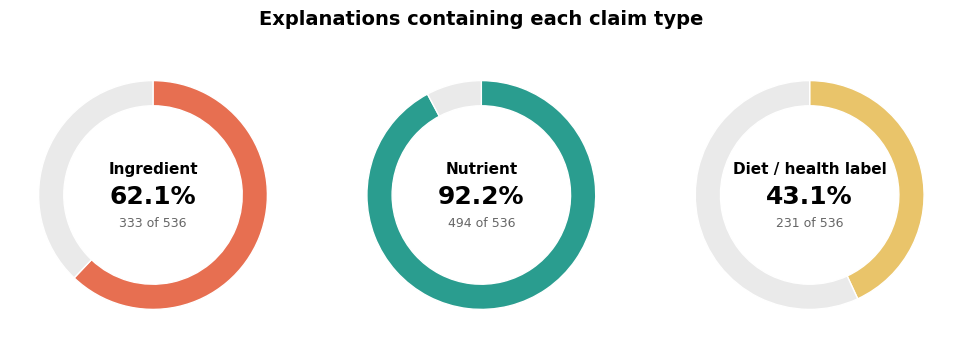

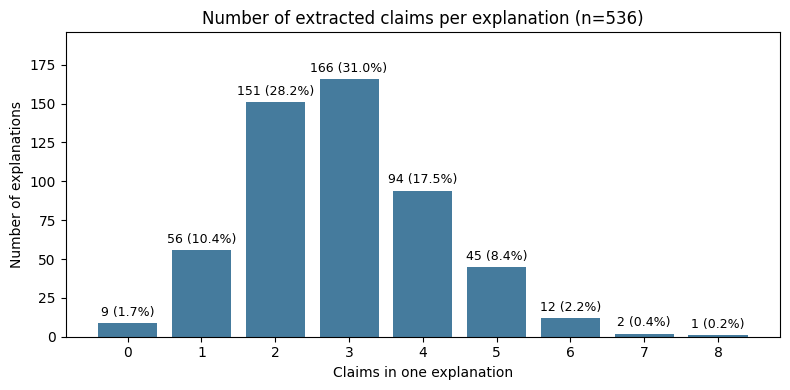

In [34]:
import matplotlib.pyplot as plt

claim_types = ["ingredient", "nutrient", "label"]

claim_labels = {
    "ingredient": "Ingredient",
    "nutrient": "Nutrient",
    "label": "Diet / health label",
}

claim_colors = {
    "ingredient": "#E76F51",
    "nutrient": "#2A9D8F",
    "label": "#E9C46A",
}


# Plot 1: Total extracted claims by type.
plot_data = claim_summary.loc[claim_types]

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    [claim_labels[claim_type] for claim_type in claim_types],
    plot_data["claims"],
    color=[claim_colors[claim_type] for claim_type in claim_types],
)

ax.bar_label(
    bars,
    labels=[f"{value:,}" for value in plot_data["claims"]],
    padding=3,
)

ax.set_title("Extracted claims by type")
ax.set_ylabel("Number of claims")
ax.set_ylim(0, plot_data["claims"].max() * 1.15)

plt.tight_layout()
plt.show()


# Plot 2: Explanation coverage shown as three donut charts.
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))

for ax, claim_type in zip(axes, claim_types):
    explanations = int(
        claim_summary.loc[claim_type, "explanations"]
    )
    percentage = float(
        claim_summary.loc[
            claim_type,
            "percent of explanations",
        ]
    )

    ax.pie(
        [percentage, 100 - percentage],
        startangle=90,
        counterclock=False,
        colors=[
            claim_colors[claim_type],
            "#EAEAEA",
        ],
        wedgeprops={
            "width": 0.22,
            "edgecolor": "white",
        },
    )

    ax.text(
        0,
        0.22,
        claim_labels[claim_type],
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
    )

    ax.text(
        0,
        -0.02,
        f"{percentage:.1f}%",
        ha="center",
        va="center",
        fontsize=18,
        fontweight="bold",
    )

    ax.text(
        0,
        -0.25,
        f"{explanations} of {explanation_count}",
        ha="center",
        va="center",
        fontsize=9,
        color="#666666",
    )

fig.suptitle(
    "Explanations containing each claim type",
    fontsize=14,
    fontweight="bold",
)

plt.tight_layout()
plt.show()


# Plot 3: Distribution of the number of claims per explanation.
claims_per_explanation = (
    claims_df
    .groupby("recommendation_id")
    .size()
    .reindex(
        claim_index["recommendation_id"],
        fill_value=0,
    )
)

claim_count_distribution = (
    claims_per_explanation
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(
    claim_count_distribution.index,
    claim_count_distribution.values,
    color="#457B9D",
)

distribution_labels = [
    f"{count} ({100 * count / explanation_count:.1f}%)"
    for count in claim_count_distribution.values
]

ax.bar_label(
    bars,
    labels=distribution_labels,
    padding=3,
    fontsize=9,
)

ax.set_title(
    f"Number of extracted claims per explanation (n={explanation_count})"
)
ax.set_xlabel("Claims in one explanation")
ax.set_ylabel("Number of explanations")
ax.set_xticks(claim_count_distribution.index)
ax.set_ylim(0, claim_count_distribution.max() * 1.18)

plt.tight_layout()
plt.show()

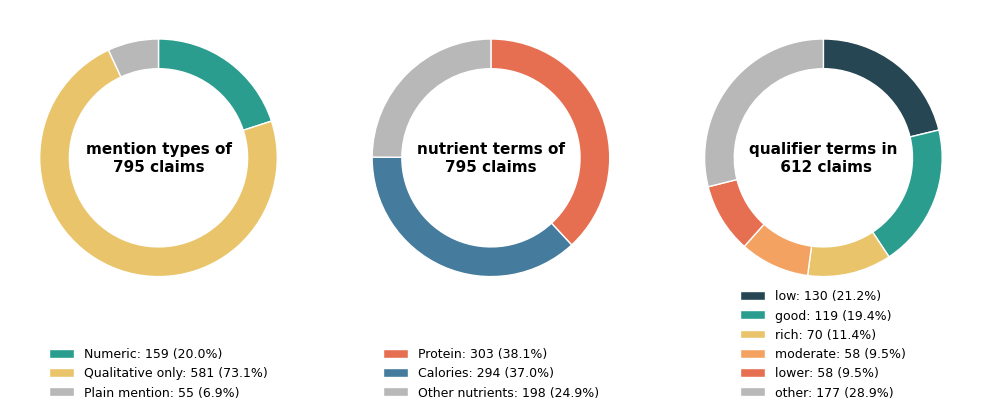

In [35]:
# Prepare nutrient claim categories.
has_number = nutrient_claims_df["number"].notna()
has_qualifier = nutrient_claims_df["qualifier"].notna()

claim_form_counts = pd.Series({
    "Numeric": has_number.sum(),
    "Qualitative only": (~has_number & has_qualifier).sum(),
    "Plain mention": (~has_number & ~has_qualifier).sum(),
})

# Group nutrient terms into protein, calories, and other terms.
term_counts = nutrient_claims_df["term"].value_counts()

nutrient_term_counts = pd.Series({
    "Protein": term_counts.get("protein", 0),
    "Calories": term_counts.get("calorie", 0),
    "Other nutrients": (
        len(nutrient_claims_df)
        - term_counts.get("protein", 0)
        - term_counts.get("calorie", 0)
    ),
})

# Group qualifiers into the five most common and all remaining qualifiers.
top_qualifier_names = [
    "low",
    "good",
    "rich",
    "moderate",
    "lower",
]

qualifier_counts = (
    nutrient_claims_df["qualifier"]
    .value_counts()
)

top_qualifier_counts = qualifier_counts.reindex(
    top_qualifier_names,
    fill_value=0,
)

qualifier_plot_counts = pd.concat([
    top_qualifier_counts,
    pd.Series({
        "other": (
            qualifier_counts.sum()
            - top_qualifier_counts.sum()
        )
    }),
])

negated_claims = int(
    nutrient_claims_df["negated"].sum()
)
def draw_donut(ax, counts, center_text, colors):
    """Draw one donut chart with counts in the legend."""
    total = counts.sum()

    wedges, _ = ax.pie(
        counts.values,
        startangle=90,
        counterclock=False,
        colors=colors,
        wedgeprops={
            "width": 0.25,
            "edgecolor": "white",
        },
    )

    ax.text(
        0,
        0,
        center_text,
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
    )

    legend_labels = [
        f"{label}: {count:,} ({100 * count / total:.1f}%)"
        for label, count in counts.items()
    ]

    ax.legend(
        wedges,
        legend_labels,
        loc="lower center",
        bbox_to_anchor=(0.5, -0.35),
        frameon=False,
        fontsize=9,
    )

fig, axes = plt.subplots(
    1,
    3,
    figsize=(11, 4.5),
    gridspec_kw={"wspace": -0.15},
)

draw_donut(
    axes[0],
    claim_form_counts,
    "mention types of\n795 claims",
    ["#2A9D8F", "#E9C46A", "#B8B8B8"],
)

draw_donut(
    axes[1],
    nutrient_term_counts,
    "nutrient terms of\n795 claims",
    ["#E76F51", "#457B9D", "#B8B8B8"],
)

draw_donut(
    axes[2],
    qualifier_plot_counts,
    "qualifier terms in\n 612 claims",
    [
        "#264653",
        "#2A9D8F",
        "#E9C46A",
        "#F4A261",
        "#E76F51",
        "#B8B8B8",
    ],
)

fig.subplots_adjust(
    left=0.02,
    right=0.98,
    top=0.88,
    bottom=0.22,
    wspace=-0.15,
)

plt.show()

### e. Save parsed explanations for later steps

Later steps read these files instead of parsing the explanations again:

| File | What it holds |
|---|---|
| `explanation_docs.spacy` | Every parsed explanation, with its `recommendation_id`, the base form of each word, and whether each word is part of the recipe title |
| `persona_values.json` | Each persona's own values: goal, diet, allergy, condition, liked / disliked ingredients and favourite cuisines |
| `user_factor_mentions.parquet` | Where each explanation names its persona's own values (outside the recipe title): the field, the value, the words and their position, and the sentence. Liked ingredients are checked with WordNet as in Step 1 |

In [36]:
from spacy.tokens import DocBin


# whether each word of the explanation belongs to the recipe title
def title_flags(doc, recommendation_id):
    return [
        not outside_title(doc[token.i:token.i + 1], recommendation_id)
        for token in doc
    ]


# attach what later steps need to one parsed explanation
def attach_parse_info(recommendation_id, doc):
    # keep the id with the parse
    doc.user_data["recommendation_id"] = recommendation_id

    # base form of every word, the same form the matching helpers compare
    doc.user_data["base_forms"] = base_forms([token.lower_ for token in doc])

    # mark title words, so later steps can skip them
    doc.user_data["in_title"] = title_flags(doc, recommendation_id)

    return doc


# rows for the persona's own values found in one parsed explanation (outside the recipe title)
def user_factor_rows(recommendation_id, persona_id, doc):
    # "gluten-free" reads as "gluten free"
    tokens = [token for token in doc if not (token.is_punct or token.is_space)]
    # lemma in context first, as the lemma tables have it ("oats" -> "oat", "lower" -> "low")
    token_bases = base_forms([token.lemma_.lower() for token in tokens])
    rows = []

    for field, value in matching_resources["persona_values"].get(persona_id, []):
        n = len(value)

        # skip stop words as the lemma tables do ("low in fat" reads as "low fat"), unless the value has them ("no red meat")
        kept = [
            (token, base)
            for token, base in zip(tokens, token_bases)
            if not token.is_stop or base in value
        ]
        words = [token for token, _ in kept]
        bases = [base for _, base in kept]
        user_food = matching_resources["liked_food_names"].get((persona_id, tuple(value)))

        for start in range(len(words) - n + 1):
            # the value's words must appear one after another
            if bases[start:start + n] != value:
                continue

            span = doc[words[start].i:words[start + n - 1].i + 1]

            # skip the recipe title
            if not outside_title(span, recommendation_id):
                continue

            # a liked item must not name a different food here (WordNet)
            if field == "liked_ingredient" and not liked_food_here(bases, start + n, value, user_food):
                continue

            rows.append({
                "recommendation_id": recommendation_id,
                "persona_id": persona_id,
                "field": field,
                "value": " ".join(value),
                "text": span.text,
                "start": span.start,  # token position in the saved parse
                "end": span.end,
                "sentence": sentence_number(span),
            })

    return rows

In [37]:
# Store every parsed explanation together with its extra information.
explanation_doc_bin = DocBin(store_user_data=True)

for recommendation_id, doc in claim_docs.items():
    explanation_doc_bin.add(attach_parse_info(recommendation_id, doc))

explanation_docs_path = processed_dir / "explanation_docs.spacy"
explanation_doc_bin.to_disk(explanation_docs_path)

# Store each persona's own values: persona_id -> [(source field, base forms)].
persona_values_path = processed_dir / "persona_values.json"

with persona_values_path.open("w", encoding="utf-8") as f:
    json.dump(matching_resources["persona_values"], f, ensure_ascii=False, indent=2)

# Store where each explanation names its persona's own values.
user_factor_mentions_df = pd.DataFrame([
    mention
    for row in claim_index.itertuples()
    for mention in user_factor_rows(row.recommendation_id, str(row.persona_id), claim_docs[row.recommendation_id])
])

user_factor_mentions_path = processed_dir / "user_factor_mentions.parquet"
user_factor_mentions_df.to_parquet(user_factor_mentions_path, index=False)

print("Saved explanations:", len(explanation_doc_bin), "->", explanation_docs_path)
print("Saved personas:", len(matching_resources["persona_values"]), "->", persona_values_path)
print(
    "Saved user factor mentions:", len(user_factor_mentions_df),
    "in", user_factor_mentions_df["recommendation_id"].nunique(), "explanations ->", user_factor_mentions_path,
)

Saved explanations: 536 -> /content/drive/MyDrive/XFoodRec_Project_Data/processed/explanation_docs.spacy
Saved personas: 40 -> /content/drive/MyDrive/XFoodRec_Project_Data/processed/persona_values.json
Saved user factor mentions: 581 in 375 explanations -> /content/drive/MyDrive/XFoodRec_Project_Data/processed/user_factor_mentions.parquet


## 2.2 & 2.3 Compare and verify extracted claims with the actual data & detect hallucination

Each claim receives verdict of `supported`, `contradicted` or `unverified`, with the source evidence and rule used.

Missing evidence is not treated as proof of correctness.

the `contradicted` verdict implies a hallucination.


prepare claims to be verified, find the original sentence corresponding to each claim.

In [38]:
# prepare the claims to be verified ###################################

verification_claims = claims_df.reset_index(drop=True)
verification_claims.insert(0, "claim_id", range(len(verification_claims)))
recipe_lookup = recipes.set_index("recipe_id").to_dict("index") # recipe to map
profile_lookup = {p["id"]: p["profile"] for p in personas} # profile to map

print("verification_claims")
print(verification_claims)

verification_claims
      claim_id recommendation_id persona_id recipe_id  rank  claim_type  \
0            0   user_01_rank_01    user_01     81968     1  ingredient   
1            1   user_01_rank_01    user_01     81968     1  ingredient   
2            2   user_01_rank_02    user_01     10614     2  ingredient   
3            3   user_01_rank_03    user_01     94673     3  ingredient   
4            4   user_01_rank_04    user_01    364252     4  ingredient   
...        ...               ...        ...       ...   ...         ...   
1546      1546   user_40_rank_09    user_40    119096     9       label   
1547      1547   user_40_rank_10    user_40     30745    10       label   
1548      1548   user_40_rank_11    user_40     14788    11       label   
1549      1549   user_40_rank_12    user_40    119417    12       label   
1550      1550   user_40_rank_15    user_40     17107    15       label   

      sentence           text         term qualifier  number unit  negated  \
0

In [39]:
# preprocess words ###################################
def verification_words(text):
    return base_forms([token.lower_ for token in text_nlp.make_doc(text) if token.is_alpha])

# recipe_id: [(original line 1, preprocessed word list 1), (original line 2, preprocessed word list 2)]
source_ingredients = {
    row.recipe_id: [(line, verification_words(line)) for line in row.ingredients_title]
    for row in recipes.itertuples()
}

print(next(iter(source_ingredients.items()))[0])
print(json.dumps(next(iter(source_ingredients.items()))[1][0],indent=2))


113861
[
  "cubed steak (4-6 pieces)",
  [
    "cub",
    "steak",
    "piece"
  ]
]


In [40]:
# find the original sentence of the claim and add to the records. ###################################

# rec_id: 'user_01_rank_01' (created during last Step 1)
# sentence list
sentences = {
    rec_id: [sentence.text for sentence in doc.sents]
    for rec_id, doc in claim_docs.items()
}

verification_claims["sentence_text"] = [
    sentences[row.recommendation_id][row.sentence] # rec_id, sentence_id -> sentence text
    for row in verification_claims.itertuples()
]

print(verification_claims)

      claim_id recommendation_id persona_id recipe_id  rank  claim_type  \
0            0   user_01_rank_01    user_01     81968     1  ingredient   
1            1   user_01_rank_01    user_01     81968     1  ingredient   
2            2   user_01_rank_02    user_01     10614     2  ingredient   
3            3   user_01_rank_03    user_01     94673     3  ingredient   
4            4   user_01_rank_04    user_01    364252     4  ingredient   
...        ...               ...        ...       ...   ...         ...   
1546      1546   user_40_rank_09    user_40    119096     9       label   
1547      1547   user_40_rank_10    user_40     30745    10       label   
1548      1548   user_40_rank_11    user_40     14788    11       label   
1549      1549   user_40_rank_12    user_40    119417    12       label   
1550      1550   user_40_rank_15    user_40     17107    15       label   

      sentence           text         term qualifier  number unit  negated  \
0            1      c

helper functions

In [41]:
# to record the verdict
def verdict(status, reason, evidence="", rule=""):
    return {"verification_status": status, "reason": reason, "evidence": evidence, "rule": rule}

# for showing detection results.
def inspect_verification(table):
    display(table["verification_status"].value_counts().to_frame("claims"))
    display(table[["claim_id", "recipe_id", "text", "verification_status", "reason", "evidence"]].head(10))

### a. Ingredients → recipe's ingredient list

Verify ingredient presence

Match the claim term with source ingredient lines.

Absence means “not found in the recorded ingredient list” under this matching rule. Negated mentions reverse the presence check.

Optional ingredients, alternatives and serving suggestions are left for review.

In [42]:
# to match for
"""
pairs / paired / pairing
served with
instead
optional
can add
"""
# for recognizing suggestions, food not included in the recipe but in fact serves as
# suggestions are not hallucination.

CONTEXT_REVIEW = re.compile(
    r"\b(?:pair(?:s|ed|ing)?|serve(?:d)? with|served alongside|substitut\w*|"
    r"swap\w*|replac\w*|instead|optional|could add|can add|can be made|"
    r"can be adapt\w*|can be customiz\w*)\b", re.I
)

In [43]:
print(source_ingredients)

{'113861': [('cubed steak (4-6 pieces)', ['cub', 'steak', 'piece']), ('oil', ['oil']), ('butter', ['butter']), ('flour', ['flour']), ('salt', ['salt']), ('onion powder', ['onion', 'powder']), ('garlic powder', ['garlic', 'powder']), ('black pepper', ['black', 'pepper']), ('cream of mushroom soup', ['cream', 'of', 'mushroom', 'soup']), ('water', ['water']), ('heavy whipping cream', ['heavy', 'whip', 'cream'])], '111212': [('Lea & Perrins Worcestershire Sauce', ['lea', 'perrin', 'worcestershire', 'sauce']), ('Lea & Perrins Worcestershire Sauce', ['lea', 'perrin', 'worcestershire', 'sauce']), ('lemon juice', ['lemon', 'juice']), ('olive oil', ['olive', 'oil']), ('instant onion', ['instant', 'onion']), ('salt', ['salt']), ('instant garlic', ['instant', 'garlic']), ('sirloin steaks', ['sirloin', 'steak']), ('butter', ['butter']), ('parsley', ['parsley'])], '497021': [('lean beef', ['lean', 'beef']), ('coleslaw mix (cabbage and carrots)', ['coleslaw', 'mix', 'cabbage', 'and', 'carrot']), ('S

In [44]:
import nltk
from nltk.corpus import wordnet as wn
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [45]:
import re

def get_wordnet_related_terms(term_tokens):
    """
    Retrieve the original term, its WordNet synonyms, and all hyponyms.
    Uses a safe BFS approach to avoid the known NLTK syn.closure() 'NoneType' bug.
    Returns a set of tuples to maintain compatibility with contains_sequence.
    """
    term_str = "_".join(term_tokens)
    valid_terms = {tuple(term_tokens)}

    # Retrieve noun synsets for the target term
    for syn in wn.synsets(term_str, pos=wn.NOUN):
        # 1. Add synonyms (lemmas of the current synset itself)
        for lemma in syn.lemmas():
            valid_terms.add(tuple(lemma.name().replace('_', ' ').lower().split()))

        # 2. Add hyponyms safely using Breadth-First Search (BFS)
        queue = list(syn.hyponyms())
        visited = set()

        while queue:
            current_syn = queue.pop(0)
            if current_syn not in visited:
                visited.add(current_syn)

                # Add all lemmas of the current hyponym
                for lemma in current_syn.lemmas():
                    valid_terms.add(tuple(lemma.name().replace('_', ' ').lower().split()))

                # Add the next level of hyponyms to the queue
                queue.extend(current_syn.hyponyms())

    return valid_terms


def verify_ingredient(row):
    sentence = row["sentence_text"] # get the raw sentence where the claim is detected

    # Context check: cannot directly verdict if the sentence involves preference, substitution, or serving context
    if CONTEXT_REVIEW.search(sentence) or about_user(
        claim_docs[row["recommendation_id"]].char_span(int(row["start_char"]), int(row["end_char"]), alignment_mode="expand").root
    ): #
        return verdict("unverified", "Preference, substitution or serving context; check the original sentence.", sentence) #

    # matching the claim term with the original sentence ingredient list ##############

    term = verification_words(row["term"]) # claim term
    lines = source_ingredients[str(row["recipe_id"])] # ingredient list of the source recipe

    # expand vocabulary: include WordNet hyponyms/synonyms (e.g. vegetables, cabbages)
    valid_term_sequences = get_wordnet_related_terms(term)

    matches = [
        raw for raw, words in lines
        if any(contains_sequence(words, list(t)) for t in valid_term_sequences)
    ]

    # if the matched ingredients is optional in the recipe, cannot verdict
    if matches and any(re.search(r"\b(?:or|optional|substitute)\b", line, re.I) for line in matches): #
        return verdict("unverified", "Matching source ingredient is optional or an alternative.", "; ".join(matches)) #

    # direct verdict: supported (adjusting for negation)
    present = bool(matches) #
    consistent = not present if row["negated"] else present #

    return verdict(
        "supported" if consistent else "contradicted", #
        "Ingredient or its hyponym found in source." if present else "Ingredient not found in the recorded list; review synonyms before final labeling.",
        "; ".join(matches) if matches else "; ".join(raw for raw, _ in lines), #
        "Normalized phrase or WordNet hyponym match; negation reverses presence."
    )

ingredient_checks = verification_claims.loc[verification_claims["claim_type"].eq("ingredient")].copy()
ingredient_checks = ingredient_checks.join(ingredient_checks.apply(verify_ingredient, axis=1).apply(pd.Series))

In [46]:
inspect_verification(ingredient_checks)

,claims
verification_status,
supported,332
unverified,119
contradicted,53


,claim_id,recipe_id,text,verification_status,reason,evidence
0,0,81968,chickpeas,supported,Ingredient or its hyponym found in source.,cooked chickpeas
1,1,81968,spinach,supported,Ingredient or its hyponym found in source.,package frozen spinach
2,2,10614,black beans,unverified,Matching source ingredient is optional or an a...,black beans (or red kidney
3,3,94673,lentils,supported,Ingredient or its hyponym found in source.,red lentils
4,4,364252,The olive oil,supported,Ingredient or its hyponym found in source.,olive oil
5,5,12569,protein-rich black beans,supported,Ingredient or its hyponym found in source.,black beans (and liquid)
6,6,27778,black beans,supported,Ingredient or its hyponym found in source.,black beans
7,7,17107,vegetables,unverified,"Preference, substitution or serving context; c...",This dish can be a hearty addition to your mea...
8,8,27778,black beans,supported,Ingredient or its hyponym found in source.,black beans
9,9,12633,meat,supported,Ingredient or its hyponym found in source.,stew meat


In [47]:
# for human inspect, contradicted

display(
    ingredient_checks.loc[
        ingredient_checks["verification_status"].eq("contradicted"),
        ["claim_id", "recipe_id", "text", "sentence_text", "reason", "evidence"]
    ]
)

,claim_id,recipe_id,text,sentence_text,reason,evidence
25,25,12569,chicken,The Chicken Rice Casserole is a comforting dis...,Ingredient not found in the recorded list; rev...,black beans (and liquid); onion; cloves garlic...
37,37,14409,strawberries,The combination of spinach and strawberries ma...,Ingredient not found in the recorded list; rev...,spinach (I pinch off the larger stems); slicer...
41,41,17471,chickpeas,It’s packed with protein from chickpeas and is...,Ingredient not found in the recorded list; rev...,vegetable oil; onions (peeled and minced); clo...
44,44,25690,whole wheat flour,Pancakes made with whole wheat flour are a who...,Ingredient not found in the recorded list; rev...,egg; milk; butter; flour; honey; baking powder...
45,45,25690,fruits,Enjoy them topped with fruits for an extra nut...,Ingredient not found in the recorded list; rev...,egg; milk; butter; flour; honey; baking powder...
53,53,34716,Rice,Ramen Fried 'Rice' is a creative take on a ric...,Ingredient not found in the recorded list; rev...,package pork-flavored ramen noodles (or smoked...
56,56,12569,tuna,The combination of beans and tuna provides a g...,Ingredient not found in the recorded list; rev...,black beans (and liquid); onion; cloves garlic...
59,59,31546,Chicken,Chicken & Long Grain Rice is a hearty meal tha...,Ingredient not found in the recorded list; rev...,lettuce; cheddar cheese; beef; package taco se...
60,60,31546,Long Grain Rice,Chicken & Long Grain Rice is a hearty meal tha...,Ingredient not found in the recorded list; rev...,lettuce; cheddar cheese; beef; package taco se...
61,61,34716,Fried Rice,Fried Rice is a classic dish that can be tailo...,Ingredient not found in the recorded list; rev...,package pork-flavored ramen noodles (or smoked...


### b. Nutrient claims → recipe's nutrition fields

Numerical and qualitative rules

Numeric amounts are compared with the source's nutrient. An explicit “per 100 g” uses that column; otherwise one serving is assumed. Values in g/mg are converted.

The project tolerance is **max(0.1 source units, 5% of the source value)**.

Unsupported units, percentages, ranges and negated numeric claims require review.

Qualitative rules use the [European Commission nutrition-claim thresholds](https://food.ec.europa.eu/food-safety/labelling-and-nutrition/nutrition-and-health-claims/nutrition-claims_en):

| Rule | Source-relative threshold |
|---|---|
| High / source of protein | At least 20% / 12% of energy from protein |
| High / source of fibre | At least 6 / 3 g per 100 g, OR 3 / 1.5 g per 100 kcal |
| Low fat / sugars | At most 3 / 5 g per 100 g |
| Low energy / sodium | At most 40 kcal / 120 mg per 100 g |

`rich` and `packed` map to high; `good` and `source` map to source. “Moderate”, “healthy”, “higher/lower” without a comparator, and unsupported nutrient/rule pairs remain unverified.

The dataset's calorie fields labelled `[cal]` are interpreted as dietary kcal.

Check qualitative thresholds

In [48]:
def qualitative_nutrition(recipe, term, qualifier):
    # only do evaluation based on EU qualitative thresholds
    if qualifier not in {"high", "source", "low"}:
        return verdict("unverified", "No absolute threshold for this qualifier.")

    # standardize unit to per-100g mass
    value, column = nutrient_value(recipe, term, "per_100g")
    if not np.isfinite(value):
        return verdict("unverified", "Source nutrient is missing.", column)

    # protein logic: evaluated by energy contribution (protein provides 4 kcal/g)
    # High: >= 20% total energy | Source: >= 12% total energy
    if term == "protein" and qualifier in {"high", "source"}:
        energy = float(recipe["calories_per_100g [cal]"])
        if not np.isfinite(energy) or energy <= 0: # invalid number
            return verdict("unverified", "Positive source energy is needed for the protein energy share.")

        share = 100 * value * 4 / energy
        threshold = 20 if qualifier == "high" else 12
        passed, evidence, rule = share >= threshold, f"Protein energy share: {share:.2f}%", f">= {threshold}% energy from protein"

    # fiber logic: Evaluated by dual criteria (mass basis OR energy basis)
    # High: >= 6g/100g or 3g/100kcal | Source: >= 3g/100g or 1.5g/100kcal
    elif term == "fiber" and qualifier in {"high", "source"}:
        energy = float(recipe["calories_per_100g [cal]"])
        if not np.isfinite(energy) or energy <= 0:
            return verdict("unverified", "Positive source energy is needed for both fibre criteria.")

        threshold = 6 if qualifier == "high" else 3
        per_energy = value * 100 / energy
        passed = value >= threshold or per_energy >= threshold / 2
        evidence = f"Fibre: {value:g} g/100g; {per_energy:.2f} g/100kcal"
        rule = f">= {threshold} g/100g OR >= {threshold / 2:g} g/100kcal"

    # low logic: Evaluated by absolute mass-based limits per 100g
    elif qualifier == "low" and term in {"fat", "sugar", "calorie", "sodium"}:
        threshold = {"fat": 3, "sugar": 5, "calorie": 40, "sodium": 120}[term]
        passed, evidence, rule = value <= threshold, f"{column}: {value:g}", f"<= {threshold} per 100g (study mass-basis rule)"

    else:
        return verdict("unverified", "No documented threshold for this nutrient/qualifier pair.", column)

    # verdict based on whether the calculated value meets the established threshold
    return verdict("supported" if passed else "contradicted", "Compared with the documented threshold.", evidence, rule)

In [49]:
NUTRIENT_FIELDS = {
    "calorie": ("calories", "cal", "kcal"),
    "protein": ("protein", "g", "g"),
    "carb": ("totalcarbohydrate", "g", "g"),
    "carbohydrate": ("totalcarbohydrate", "g", "g"),
    "fat": ("totalfat", "g", "g"),
    "fiber": ("dietaryfiber", "g", "g"),
    "sugar": ("sugars", "g", "g"),
    "sodium": ("sodium", "mg", "mg"),
    "cholesterol": ("cholesterol", "mg", "mg")
}

NUMERIC_REL_TOL = 0.05
NUMERIC_ABS_TOL = 0.1

# according to the basis, return the true value
def nutrient_value(recipe, term, basis):
    stem, column_unit, _ = NUTRIENT_FIELDS[term]
    column = f"{stem}_{basis} [{column_unit}]"
    return float(recipe[column]), column

In [50]:
QUALIFIER_MAP = {"high": "high", "rich": "high", "packed": "high", "good": "source", "source": "source", "low": "low"}

def verify_nutrient(row):
    recipe = recipe_lookup[str(row["recipe_id"])]
    term, sentence = row["term"], row["sentence_text"]

    if term not in NUTRIENT_FIELDS: # not detected
        return verdict("unverified", "No source-column mapping for the extracted nutrient.")
    if CONTEXT_REVIEW.search(sentence): # the explanation suggests a modification
        return verdict("unverified", "Recipe modification or serving context requires review.", sentence)

    results = {}

    # Numeric Claim Verification
    if pd.notna(row["number"]):
        # default assumption is per serving
        basis = "per_100g" if re.search(r"\b(?:per|/|in|for)\s*100\s*g(?:rams?)?\b", sentence, re.I) else "per_serving"
        actual, column = nutrient_value(recipe, term, basis)
        _, _, src_unit = NUTRIENT_FIELDS[term]

        raw_unit = str(row["unit"]).lower() if pd.notna(row["unit"]) else ""
        unit = {"gram": "g", "grams": "g", "milligram": "mg", "milligrams": "mg", "calorie": "kcal", "calories": "kcal"}.get(raw_unit, raw_unit)
        unit = src_unit if unit in {"", term} else unit

        factor = {("g", "mg"): 1000, ("mg", "g"): 0.001}.get((unit, src_unit), 1 if unit == src_unit else None)
        ambiguous = re.search(r"%|percent|per\s*100\s*ml|\bbetween\b|\d\s*[-–]\s*\d|\b(?:less|more) than\b|\bup to\b", sentence, re.I)

        if row["negated"] or ambiguous or factor is None or not np.isfinite(actual):
            results["numeric"] = verdict("unverified", "Negation, range, unsupported unit/basis, or missing source value.", sentence)
        else:
            claimed = float(row["number"]) * factor
            tolerance = max(NUMERIC_ABS_TOL, NUMERIC_REL_TOL * abs(actual))
            passed = abs(claimed - actual) <= tolerance
            results["numeric"] = verdict(
                "supported" if passed else "contradicted",
                "Compared with source nutrition.",
                f"Claim={claimed:g} {src_unit}; {column}={actual:g}; tolerance={tolerance:g}",
                f"Absolute diff <= max(0.1, 5% of source); basis={basis}; inferred unit={unit==src_unit}"
            )

    # Qualitative Claim Verification
    if pd.notna(row["qualifier"]):
        qualifier = str(row["qualifier"]).lower().strip()
        results["qualitative"] = (
            verdict("unverified", "Negated qualitative wording requires a scope check.") if row["negated"]
            else qualitative_nutrition(recipe, term, QUALIFIER_MAP.get(qualifier, qualifier))
        )

    if not results:
        return verdict("unverified", "Plain nutrient mention has no numerical or qualitative claim to check.")

    # Aggregate Final Verdict
    statuses = set(x["verification_status"] for x in results.values())
    status = "contradicted" if "contradicted" in statuses else "unverified" if "unverified" in statuses else "supported"

    result = verdict(
        status,
        " | ".join(f"{k}: {v['reason']}" for k, v in results.items()),
        " | ".join(f"{k}: {v['evidence']}" for k, v in results.items()),
        " | ".join(f"{k}: {v['rule']}" for k, v in results.items())
    )
    result.update({f"{k}_status": v["verification_status"] for k, v in results.items()})

    return result

In [51]:
nutrient_checks = verification_claims.loc[verification_claims["claim_type"].eq("nutrient")].copy()
nutrient_checks = nutrient_checks.join(nutrient_checks.apply(verify_nutrient, axis=1).apply(pd.Series))
inspect_verification(nutrient_checks)



,claims
verification_status,
unverified,369
supported,311
contradicted,115


,claim_id,recipe_id,text,verification_status,reason,evidence
504,504,81968,packed with protein,contradicted,qualitative: Compared with the documented thre...,qualitative: Protein energy share: 17.23%
505,505,10614,high protein,supported,qualitative: Compared with the documented thre...,qualitative: Protein energy share: 23.02%
506,506,10614,low in fat,supported,qualitative: Compared with the documented thre...,qualitative: totalfat_per_100g [g]: 1.2
507,507,94673,rich in protein,supported,qualitative: Compared with the documented thre...,qualitative: Protein energy share: 20.11%
508,508,94673,rich in protein and fiber,supported,qualitative: Compared with the documented thre...,qualitative: Fibre: 10.6 g/100g; 5.86 g/100kcal
509,509,364252,low in calories,contradicted,qualitative: Compared with the documented thre...,qualitative: calories_per_100g [cal]: 82.9
510,510,364252,healthy fats,unverified,qualitative: No absolute threshold for this qu...,qualitative:
511,511,12569,protein-rich,contradicted,qualitative: Compared with the documented thre...,qualitative: Protein energy share: 8.39%
512,512,12569,carbs,unverified,Plain nutrient mention has no numerical or qua...,
513,513,27778,good amount of protein,supported,qualitative: Compared with the documented thre...,qualitative: Protein energy share: 15.91%


In [52]:
contradicted = nutrient_checks[
    nutrient_checks[
        ["numeric_status", "qualitative_status"]
    ].eq("contradicted").any(axis=1)
]

display(contradicted)

,claim_id,recommendation_id,persona_id,recipe_id,rank,claim_type,sentence,text,term,qualifier,...,negated,start_char,end_char,sentence_text,verification_status,reason,evidence,rule,qualitative_status,numeric_status
504,504,user_01_rank_01,user_01,81968,1,nutrient,0,packed with protein,protein,packed,...,False,53,72,Chickpeas With Spinach (Greek) is a fantastic ...,contradicted,qualitative: Compared with the documented thre...,qualitative: Protein energy share: 17.23%,qualitative: >= 20% energy from protein,contradicted,NaN
509,509,user_01_rank_04,user_01,364252,4,nutrient,0,low in calories,calorie,low,...,False,118,133,My Favorite Sauteed Kale is a nutrient-dense o...,contradicted,qualitative: Compared with the documented thre...,qualitative: calories_per_100g [cal]: 82.9,qualitative: <= 40 per 100g (study mass-basis ...,contradicted,NaN
511,511,user_01_rank_05,user_01,12569,5,nutrient,0,protein-rich,protein,rich,...,False,35,47,Hearty Black Beans & Rice combines protein-ric...,contradicted,qualitative: Compared with the documented thre...,qualitative: Protein energy share: 8.39%,qualitative: >= 20% energy from protein,contradicted,NaN
516,516,user_01_rank_07,user_01,17107,7,nutrient,0,good amount of protein,protein,good,...,False,79,101,"Fried Cabbage, while higher in calories, offer...",contradicted,qualitative: Compared with the documented thre...,qualitative: Protein energy share: 11.06%,qualitative: >= 12% energy from protein,contradicted,NaN
519,519,user_01_rank_09,user_01,11424,9,nutrient,0,protein-rich,protein,rich,...,False,21,33,"Hummus is a classic, protein-rich dip, perfect...",contradicted,qualitative: Compared with the documented thre...,qualitative: Protein energy share: 15.00%,qualitative: >= 20% energy from protein,contradicted,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1249,1249,user_38_rank_15,user_38,8594,15,nutrient,1,good balance of carbohydrates and protein,protein,good,...,False,138,179,It provides a moderate calorie option with a g...,contradicted,qualitative: Compared with the documented thre...,qualitative: Protein energy share: 10.36%,qualitative: >= 12% energy from protein,contradicted,NaN
1264,1264,user_39_rank_08,user_39,21843,8,nutrient,1,rich in fiber and protein,protein,rich,...,False,87,112,"This dish is rich in fiber and protein, making...",contradicted,qualitative: Compared with the documented thre...,qualitative: Protein energy share: 17.19%,qualitative: >= 20% energy from protein,contradicted,NaN
1265,1265,user_39_rank_09,user_39,130781,9,nutrient,0,low-calorie,calorie,low,...,False,25,36,Sweet Pickle Relish is a low-calorie option at...,contradicted,qualitative: Compared with the documented thre...,qualitative: calories_per_100g [cal]: 141.7,qualitative: <= 40 per 100g (study mass-basis ...,contradicted,NaN
1278,1278,user_40_rank_03,user_40,26632,3,nutrient,1,low in calories at just 82.4,calorie,low,...,False,99,127,"It's low in calories at just 82.4 per serving,...",contradicted,numeric: Compared with source nutrition. | qua...,numeric: Claim=82.4 kcal; calories_per_serving...,"numeric: Absolute diff <= max(0.1, 5% of sourc...",contradicted,supported


### c. Diet/health-label claims → both the recipe's ingredients and the persona's restrictions/allergies/conditions

Ingredient conflict rules

Explicit ingredient groups below provide a reproducible screen for common dietary exclusions and the nine recorded allergy categories. The lists are project matching rules, not a complete allergen database. Alternatives, “free-from” and imitation products require review. Recipe tags are not used as ground truth.

A detected forbidden ingredient contradicts a positive compatibility claim. No detected conflict alone does **not** establish allergen safety, gluten content, religious certification or disease suitability. Unsupported diets and clinical outcomes remain unverified. Full persona fields (including `other`) are retained for review.

In [53]:
FOOD_GROUPS = {
    "red_meat": "beef|pork|bacon|ham|lamb|veal|venison|prosciutto|pancetta|lard|pepperoni",
    "poultry": "chicken|turkey|duck|goose",
    "fish": "fish|salmon|tuna|anchovy|sardine|cod|haddock|trout|tilapia|fish sauce",
    "shellfish": "shrimp|prawn|crab|lobster|clam|mussel|oyster|scallop|crayfish",
    "milk": "milk|cream|butter|cheese|yogurt|yoghurt|whey|casein|ghee|parmesan|cheddar|mozzarella|feta",
    "eggs": "egg|mayonnaise|meringue",
    "peanuts": "peanut|groundnut",
    "tree_nuts": "almond|walnut|cashew|pecan|pistachio|hazelnut|macadamia|brazil nut",
    "sesame": "sesame|tahini",
    "soy": "soy|soya|tofu|tempeh|edamame|miso",
    "wheat": "wheat|semolina|bulgur|couscous|seitan|spelt|farro",
    "gluten_grains": "wheat|semolina|bulgur|couscous|seitan|spelt|farro|barley|rye",
    "apples": "apple|applesauce",
    "gelatin": "gelatin|gelatine",
    "honey": "honey"
}
FOOD_GROUPS = {group: [verification_words(term) for term in terms.split("|")] for group, terms in FOOD_GROUPS.items()}
DIET_GROUPS = {
    "vegan": ["red_meat", "poultry", "fish", "shellfish", "milk", "eggs", "gelatin", "honey"],
    "vegetarian": ["red_meat", "poultry", "fish", "shellfish", "gelatin"],
    "pescatarian": ["red_meat", "poultry"],
    "no red meat": ["red_meat"],
    "dairy free": ["milk"],
    "gluten free": ["gluten_grains"]
}
ALLERGY_GROUPS = {
    "apples": "apples", "eggs": "eggs", "milk": "milk", "peanuts": "peanuts",
    "sesame": "sesame", "shellfish": "shellfish", "soy": "soy", "tree nuts": "tree_nuts", "wheat": "wheat"
}

def label_key(text):
    return re.sub(r"[^a-z0-9]+", " ", text.lower()).strip()



In [54]:
def forbidden_ingredients(recipe_id, groups):
    certain, uncertain = [], []
    for raw, words in source_ingredients[str(recipe_id)]:
        matched_groups = [group for group in groups if any(
            contains_sequence(words, term) for term in FOOD_GROUPS[group]
        )]
        if not matched_groups:
            continue
        line = " ".join(words)
        ambiguous = re.search(r"\b(?:or|optional|free|substitute|imitation|vegan|vegetarian|non dairy|nondairy)\b", line)
        # A plant-based dairy alternative is ambiguous for milk, but still evidence for its own allergen.
        plant_dairy = re.search(r"\b(?:coconut|almond|soy|soya|oat|rice|cashew|peanut|apple|cocoa)\b.*\b(?:milk|cream|butter|cheese|yogurt)\b", line)
        if plant_dairy and set(matched_groups) == {"milk"}:
            ambiguous = True
        (uncertain if ambiguous else certain).append(raw)
    return certain, uncertain



In [55]:
NUTRITION_LABELS = {"high protein": ("protein", "high"), "low fat": ("fat", "low"), "low sodium": ("sodium", "low")}

def check_profile_requirement(recipe_id, field, value):
    key = label_key(value)
    if field == "foodAllergies":
        groups = [ALLERGY_GROUPS[key]] if key in ALLERGY_GROUPS else None
    elif field == "healthConditions":
        groups = ["gluten_grains"] if key == "celiac disease" else None
    else:
        groups = DIET_GROUPS.get(key)
    if groups is not None:
        conflicts, ambiguous = forbidden_ingredients(recipe_id, groups)
        if conflicts:
            return verdict("contradicted", "Explicit source ingredient conflicts with this requirement.", "; ".join(conflicts), f"Ingredient exclusion: {key}")
        return verdict("unverified", "No explicit conflict found; composition/certification is insufficient to confirm compatibility.", "; ".join(ambiguous), f"Ingredient exclusion: {key}")
    if field == "dietaryRestrictions" and key in NUTRITION_LABELS:
        return qualitative_nutrition(recipe_lookup[str(recipe_id)], *NUTRITION_LABELS[key])
    return verdict("unverified", "No justified compatibility rule for this diet or health condition.", value)

Check each persona against the recommended recipe

`persona_compatibility_df` records each selected restriction, allergy and condition, plus free-text notes requiring review. It checks the recommendation itself, separately from whether the explanation falsely claims compatibility. These rows must not be counted automatically as explanation hallucinations.

In [56]:
compatibility_rows = []
for rec in claim_index.to_dict("records"):
    profile = profile_lookup[rec["persona_id"]]["dietaryProfile"]
    for field in ["dietaryRestrictions", "foodAllergies", "healthConditions"]:
        for value in profile[field]["selected"]:
            compatibility_rows.append({**rec, "profile_field": field, "requirement": value,
                **check_profile_requirement(rec["recipe_id"], field, value)})
        note = profile[field]["other"].strip()
        if note:
            compatibility_rows.append({**rec, "profile_field": field + ".other", "requirement": note,
                **verdict("unverified", "Free-text persona requirement needs review.", note)})
persona_compatibility_df = pd.DataFrame(compatibility_rows)
display(pd.crosstab(persona_compatibility_df["profile_field"], persona_compatibility_df["verification_status"]))
display(persona_compatibility_df.loc[persona_compatibility_df["verification_status"].eq("contradicted")].head(10))

verification_status,contradicted,supported,unverified
profile_field,,,
dietaryRestrictions,48,53,365
dietaryRestrictions.other,0,0,536
foodAllergies,8,0,162
foodAllergies.other,0,0,66
healthConditions,0,0,414
healthConditions.other,0,0,152


,recommendation_id,persona_id,recipe_id,rank,profile_field,requirement,verification_status,reason,evidence,rule
12,user_01_rank_07,user_01,17107,7,dietaryRestrictions,Vegan,contradicted,Explicit source ingredient conflicts with this...,bacon,Ingredient exclusion: vegan
117,user_04_rank_03,user_04,73051,3,dietaryRestrictions,Vegetarian,contradicted,Explicit source ingredient conflicts with this...,slices bacon,Ingredient exclusion: vegetarian
228,user_06_rank_08,user_06,105281,8,dietaryRestrictions,High Protein,contradicted,Compared with the documented threshold.,Protein energy share: 12.00%,>= 20% energy from protein
232,user_06_rank_09,user_06,26470,9,dietaryRestrictions,High Protein,contradicted,Compared with the documented threshold.,Protein energy share: 11.64%,>= 20% energy from protein
236,user_06_rank_10,user_06,26440,10,dietaryRestrictions,High Protein,contradicted,Compared with the documented threshold.,Protein energy share: 11.22%,>= 20% energy from protein
240,user_06_rank_11,user_06,21623,11,dietaryRestrictions,High Protein,contradicted,Compared with the documented threshold.,Protein energy share: 10.29%,>= 20% energy from protein
244,user_06_rank_12,user_06,27130,12,dietaryRestrictions,High Protein,contradicted,Compared with the documented threshold.,Protein energy share: 12.23%,>= 20% energy from protein
268,user_07_rank_04,user_07,30469,4,dietaryRestrictions,Pescatarian,contradicted,Explicit source ingredient conflicts with this...,chicken bouillon cube,Ingredient exclusion: pescatarian
468,user_11_rank_04,user_11,138356,4,dietaryRestrictions,High Protein,contradicted,Compared with the documented threshold.,Protein energy share: 8.64%,>= 20% energy from protein
480,user_11_rank_08,user_11,20780,8,dietaryRestrictions,High Protein,contradicted,Compared with the documented threshold.,Protein energy share: 12.26%,>= 20% energy from protein


Verify extracted labels

A label's occurrence in the user's profile is recorded separately from recipe compatibility. Generic goals and medical-benefit claims cannot be validated by matching a profile label. Sentences acknowledging incompatibility or proposing modifications are sent for review so an honest warning is not automatically called false. Negated labels are also reviewed because 2.1 does not fully resolve negation scope.

In [57]:
compatibility_by_rec = {key: frame for key, frame in persona_compatibility_df.groupby("recommendation_id")}

def verify_label(row):
    profile = profile_lookup[row["persona_id"]]
    sentence = row["sentence_text"]
    key = label_key(row["term"])
    profile_values = [profile["dietary_goal"]] + [
        value for field in ["dietaryRestrictions", "foodAllergies", "healthConditions"]
        for value in profile["dietaryProfile"][field]["selected"]
    ]
    # Compare normalized words to the label produced by 2.1 (e.g. plural normalization).
    mentioned_profile = [value for value in profile_values if verification_words(value) == verification_words(row["term"])]
    checks = compatibility_by_rec.get(row["recommendation_id"])
    conflicts = [] if checks is None else checks.loc[checks["verification_status"].eq("contradicted"), "requirement"].tolist()
    extra = {"persona_label_match": bool(mentioned_profile), "matched_profile_values": "; ".join(mentioned_profile),
             "persona_conflicts": "; ".join(conflicts)}
    warning = re.search(r"\b(?:not|doesn't|does not|isn't|is not|doesn’t|isn’t)\b|\b(?:despite|although|however|caution)\b", sentence, re.I)
    if row["negated"] or warning or CONTEXT_REVIEW.search(sentence):
        return {**verdict("unverified", "Negation, warning or modification: review the intended compatibility claim.", sentence), **extra}
    if key in DIET_GROUPS:
        result = check_profile_requirement(row["recipe_id"], "dietaryRestrictions", key)
    elif key in NUTRITION_LABELS:
        # A user requirement alone does not assert that the recipe meets a nutrient threshold.
        if re.search(r"\b(?:align\w*|match\w*|fit\w*|meet\w*|support\w*|suitab\w*|ideal|perfect|complement\w*)\b", sentence, re.I):
            result = check_profile_requirement(row["recipe_id"], "dietaryRestrictions", key)
        else:
            result = verdict("unverified", "Profile nutrient label is mentioned without an explicit compatibility statement.", sentence)
    else:
        result = verdict("unverified", "Goal/condition or unsupported diet requires a specific evidence rule; profile agreement is not proof.", sentence)
    return {**result, **extra}

label_checks = verification_claims.loc[verification_claims["claim_type"].eq("label")].copy()
label_checks = label_checks.join(label_checks.apply(verify_label, axis=1).apply(pd.Series))
inspect_verification(label_checks)
display(label_checks[["text", "persona_label_match", "matched_profile_values", "persona_conflicts", "verification_status"]].head(10))

,claims
verification_status,
unverified,242
supported,6
contradicted,4


,claim_id,recipe_id,text,verification_status,reason,evidence
1299,1299,81968,muscle gain,unverified,Goal/condition or unsupported diet requires a ...,Chickpeas With Spinach (Greek) is a fantastic ...
1300,1300,10614,muscle gain,unverified,Goal/condition or unsupported diet requires a ...,"Refried Beans offers a high protein content, m..."
1301,1301,94673,muscle gain,unverified,Goal/condition or unsupported diet requires a ...,Egyptian Red Lentil Soup is rich in protein an...
1302,1302,364252,muscle gain,unverified,Goal/condition or unsupported diet requires a ...,"The olive oil adds healthy fats, making it a b..."
1303,1303,27778,muscle gain,unverified,Goal/condition or unsupported diet requires a ...,It's a delightful way to enjoy black beans whi...
1304,1304,27778,muscle gain,unverified,Goal/condition or unsupported diet requires a ...,It's a delightful way to enjoy black beans whi...
1305,1305,46221,muscle gain,unverified,Goal/condition or unsupported diet requires a ...,Classic Black Beans and Rice is a traditional ...
1306,1306,12633,vegan,unverified,"Negation, warning or modification: review the ...",While it doesn't align perfectly with your veg...
1307,1307,46221,muscle gain,unverified,Goal/condition or unsupported diet requires a ...,Classic Black Beans and Rice is a traditional ...
1308,1308,94673,muscle gain,unverified,Goal/condition or unsupported diet requires a ...,Egyptian Red Lentil Soup is rich in protein an...


,text,persona_label_match,matched_profile_values,persona_conflicts,verification_status
1299,muscle gain,True,Muscle Gain,,unverified
1300,muscle gain,True,Muscle Gain,,unverified
1301,muscle gain,True,Muscle Gain,,unverified
1302,muscle gain,True,Muscle Gain,,unverified
1303,muscle gain,True,Muscle Gain,,unverified
1304,muscle gain,True,Muscle Gain,,unverified
1305,muscle gain,True,Muscle Gain,,unverified
1306,vegan,True,Vegan,,unverified
1307,muscle gain,True,Muscle Gain,,unverified
1308,muscle gain,True,Muscle Gain,,unverified


Combine and save verification results

`verified_claims_df` keeps every extracted claim and its evidence. `persona_compatibility_df` is a separate recommendation/profile screen. `unverified` rows and automatic contradictions form the review queue. Counts below are claim-level results, not the explanation-level hallucination rate or a validation of the verifier.

In [58]:
verified_claims_df = pd.concat([ingredient_checks, nutrient_checks, label_checks], ignore_index=True).sort_values("claim_id")
verification_summary = pd.crosstab(verified_claims_df["claim_type"], verified_claims_df["verification_status"]).reindex(
    columns=["supported", "contradicted", "unverified"], fill_value=0
)
display(verification_summary)
review_claims_df = verified_claims_df.loc[verified_claims_df["verification_status"].ne("supported")].copy()

verified_claims_df.to_parquet(processed_dir / "verified_claims.parquet", index=False)
persona_compatibility_df.to_parquet(processed_dir / "persona_compatibility.parquet", index=False)
print("Saved verified_claims.parquet and persona_compatibility.parquet")
print("Claims for manual review:", len(review_claims_df))

verification_status,supported,contradicted,unverified
claim_type,,,
ingredient,332,53,119
label,6,4,242
nutrient,311,115,369


Saved verified_claims.parquet and persona_compatibility.parquet
Claims for manual review: 902


explanation-level hallucination annotation

In [59]:
# Map claim types to readable hallucination types.
hallucination_type_labels = {
    "ingredient": "ingredient",
    "nutrient": "nutrition",
    "label": "diet/health label",
}

# Keep only automatically contradicted claims.
contradicted_claims = verified_claims_df[
    verified_claims_df["verification_status"].eq("contradicted")
].copy()

# Aggregate contradicted claims by explanation.
hallucination_summary = (
    contradicted_claims
    .groupby("recommendation_id")
    .agg(
        false_claims=("claim_id", "size"),
        claim_types=(
            "claim_type",
            lambda values: sorted(set(values)),
        ),
    )
    .reset_index()
)

hallucination_summary["hallucination_types"] = (
    hallucination_summary["claim_types"]
    .apply(
        lambda types: [
            hallucination_type_labels[claim_type]
            for claim_type in types
        ]
    )
)

hallucination_summary = hallucination_summary.drop(
    columns="claim_types"
)

# Count unverified claims requiring manual review.
review_counts = (
    verified_claims_df[
        verified_claims_df["verification_status"].eq("unverified")
    ]
    .groupby("recommendation_id")
    .size()
    .rename("unverified_claims")
    .reset_index()
)

# Create one row per explanation.
explanation_hallucination_df = (
    claim_index
    .drop_duplicates("recommendation_id")
    .merge(
        hallucination_summary,
        on="recommendation_id",
        how="left",
        validate="one_to_one",
    )
    .merge(
        review_counts,
        on="recommendation_id",
        how="left",
        validate="one_to_one",
    )
)

explanation_hallucination_df["false_claims"] = (
    explanation_hallucination_df["false_claims"]
    .fillna(0)
    .astype(int)
)

explanation_hallucination_df["unverified_claims"] = (
    explanation_hallucination_df["unverified_claims"]
    .fillna(0)
    .astype(int)
)

explanation_hallucination_df["hallucination_types"] = (
    explanation_hallucination_df["hallucination_types"]
    .apply(lambda value: value if isinstance(value, list) else [])
)

explanation_hallucination_df["hallucinated"] = (
    explanation_hallucination_df["false_claims"] > 0
)

# Distinguish unresolved explanations from clean automatic results.
explanation_hallucination_df["status"] = np.select(
    [
        explanation_hallucination_df["hallucinated"],
        explanation_hallucination_df["unverified_claims"] > 0,
    ],
    [
        "hallucinated",
        "needs review",
    ],
    default="no detected hallucination",
)

# Add the original explanation text.
explanation_hallucination_df["explanation"] = (
    explanation_hallucination_df["recommendation_id"]
    .map(claim_texts)
)

display(explanation_hallucination_df.head())

,recommendation_id,persona_id,recipe_id,rank,false_claims,hallucination_types,unverified_claims,hallucinated,status,explanation
0,user_01_rank_01,user_01,81968,1,1,[nutrition],1,True,hallucinated,Chickpeas With Spinach (Greek) is a fantastic ...
1,user_01_rank_02,user_01,10614,2,0,[],2,False,needs review,"Refried Beans offers a high protein content, m..."
2,user_01_rank_03,user_01,94673,3,0,[],1,False,needs review,Egyptian Red Lentil Soup is rich in protein an...
3,user_01_rank_04,user_01,364252,4,1,[nutrition],2,True,hallucinated,My Favorite Sauteed Kale is a nutrient-dense o...
4,user_01_rank_05,user_01,12569,5,1,[nutrition],1,True,hallucinated,Hearty Black Beans & Rice combines protein-ric...


In [60]:
display(
    explanation_hallucination_df["status"]
    .value_counts()
    .to_frame("explanations")
)

for hallucination_type in [
    "ingredient",
    "nutrition",
    "diet/health label",
]:
    count = explanation_hallucination_df[
        "hallucination_types"
    ].apply(
        lambda types: hallucination_type in types
    ).sum()

    print(
        hallucination_type,
        count,
        f"({100 * count / len(explanation_hallucination_df):.1f}%)",
    )

,explanations
status,
needs review,330
hallucinated,145
no detected hallucination,61


ingredient 47 (8.8%)
nutrition 104 (19.4%)
diet/health label 4 (0.7%)


## 2.4 Do longer explanations or certain persona types hallucinate more?

Conclusive explanations used: 206 / 536
Unresolved negatives excluded: 330


,explanations,personas,min_words,median_words,max_words,hallucination_rate,false_claims,extracted_claims,contradicted_claim_rate
length_quartile,,,,,,,,,
Q1 shortest,52,22,24,29.0,31,65.4%,40,124,32.3%
Q2,51,24,31,33.0,34,70.6%,45,121,37.2%
Q3,51,28,34,36.0,39,70.6%,38,155,24.5%
Q4 longest,52,20,39,42.0,52,75.0%,49,162,30.2%


Longest minus shortest quartile: +9.6% (persona-clustered 95% bootstrap CI -17.0% to +33.2%).
Length conclusion: the data do not show a clear difference between the longest and shortest explanations.
Use the contradicted-claim rate above to judge whether any increase is more than added claim exposure.


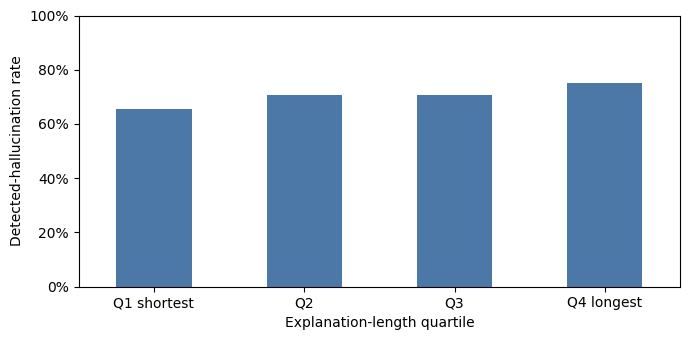

In [61]:
# Reuse the exact word-count rule from data_exploration.ipynb.
word_pattern = re.compile(r"\b\w+(?:[-'’]\w+)*\b")
association_df = explanation_hallucination_df.copy()
association_df["word_count"] = (
    association_df["explanation"].str.findall(word_pattern).str.len()
)

# A positive contradiction is conclusive; an otherwise-negative row with an
# unverified claim is not safe to treat as a clean negative.
association_df["conclusive"] = (
    association_df["hallucinated"]
    | association_df["unverified_claims"].eq(0)
)
analysis_df = association_df.loc[association_df["conclusive"]].copy()
analysis_df["hallucinated"] = analysis_df["hallucinated"].astype(int)

print(f"Conclusive explanations used: {len(analysis_df)} / {len(association_df)}")
print(
    "Unresolved negatives excluded:",
    int((~association_df["conclusive"]).sum()),
)

# rank(method='first') guarantees four equally sized bins even when word counts tie.
length_order = ["Q1 shortest", "Q2", "Q3", "Q4 longest"]
analysis_df["length_quartile"] = pd.qcut(
    analysis_df["word_count"].rank(method="first"),
    q=4,
    labels=length_order,
)

# Also show a claim-normalized rate: longer text has more chances to make a claim.
claim_opportunities = (
    verified_claims_df.assign(
        contradicted=verified_claims_df["verification_status"].eq("contradicted")
    )
    .groupby("recommendation_id")
    .agg(extracted_claims=("claim_id", "size"), contradicted_claims=("contradicted", "sum"))
)
analysis_df = analysis_df.join(claim_opportunities, on="recommendation_id")
analysis_df[["extracted_claims", "contradicted_claims"]] = (
    analysis_df[["extracted_claims", "contradicted_claims"]].fillna(0).astype(int)
)

length_summary = (
    analysis_df.groupby("length_quartile", observed=False)
    .agg(
        explanations=("recommendation_id", "size"),
        personas=("persona_id", "nunique"),
        min_words=("word_count", "min"),
        median_words=("word_count", "median"),
        max_words=("word_count", "max"),
        hallucination_rate=("hallucinated", "mean"),
        false_claims=("contradicted_claims", "sum"),
        extracted_claims=("extracted_claims", "sum"),
    )
)
length_summary["contradicted_claim_rate"] = (
    length_summary["false_claims"]
    / length_summary["extracted_claims"].replace(0, np.nan)
)
display(
    length_summary.style.format({
        "median_words": "{:.1f}",
        "hallucination_rate": "{:.1%}",
        "contradicted_claim_rate": "{:.1%}",
    })
)

# Cluster bootstrap: resample whole personas, preserving within-person dependence.
rng = np.random.default_rng(42)
def long_short_difference(frame):
    rates = frame.groupby("length_quartile", observed=False)["hallucinated"].mean()
    return rates.get("Q4 longest", np.nan) - rates.get("Q1 shortest", np.nan)

observed_length_difference = long_short_difference(analysis_df)
persona_blocks = [group for _, group in analysis_df.groupby("persona_id")]
bootstrap_differences = np.array([
    long_short_difference(pd.concat(
        [persona_blocks[i] for i in rng.integers(0, len(persona_blocks), len(persona_blocks))],
        ignore_index=True,
    ))
    for _ in range(2000)
])
bootstrap_differences = bootstrap_differences[np.isfinite(bootstrap_differences)]
length_ci = np.quantile(bootstrap_differences, [0.025, 0.975])

print(
    f"Longest minus shortest quartile: {observed_length_difference:+.1%} "
    f"(persona-clustered 95% bootstrap CI {length_ci[0]:+.1%} to {length_ci[1]:+.1%})."
)
if length_ci[0] > 0:
    print("Length conclusion: longer explanations have a clearly higher detected-hallucination rate.")
elif length_ci[1] < 0:
    print("Length conclusion: longer explanations have a clearly lower detected-hallucination rate.")
else:
    print("Length conclusion: the data do not show a clear difference between the longest and shortest explanations.")
print("Use the contradicted-claim rate above to judge whether any increase is more than added claim exposure.")

ax = length_summary["hallucination_rate"].plot(
    kind="bar", ylim=(0, 1), figsize=(7, 3.5), color="#4C78A8"
)
ax.set(xlabel="Explanation-length quartile", ylabel="Detected-hallucination rate")
ax.yaxis.set_major_formatter(lambda value, position: f"{value:.0%}")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [62]:
# Collapse to one equally weighted outcome rate per persona.
persona_rates = (
    analysis_df.groupby("persona_id")
    .agg(
        explanations=("recommendation_id", "size"),
        hallucinations=("hallucinated", "sum"),
        hallucination_rate=("hallucinated", "mean"),
        median_words=("word_count", "median"),
    )
    .reset_index()
)
persona_profiles = personas_df.rename(columns={"id": "persona_id"}).copy()
persona_profiles["persona_id"] = persona_profiles["persona_id"].astype(str)
persona_rates["persona_id"] = persona_rates["persona_id"].astype(str)

persona_fields = {
    "Gender": ("profile.gender", False),
    "Dietary goal": ("profile.dietary_goal", False),
    "Activity level": ("profile.activityLevel", False),
    "Dietary restriction": ("profile.dietaryProfile.dietaryRestrictions.selected", True),
    "Food allergy": ("profile.dietaryProfile.foodAllergies.selected", True),
    "Health condition": ("profile.dietaryProfile.healthConditions.selected", True),
}

# Long table: a persona can belong to multiple categories for multi-select fields.
membership_rows = []
for factor, (column, is_multiselect) in persona_fields.items():
    for row in persona_profiles[["persona_id", column]].itertuples(index=False, name=None):
        persona_id, raw_value = row
        if is_multiselect:
            values = list(raw_value) if isinstance(raw_value, (list, tuple, np.ndarray)) else []
            values = values or ["None selected"]
        else:
            values = [raw_value]
        for value in values:
            if pd.notna(value) and str(value).strip():
                membership_rows.append({"persona_id": persona_id, "factor": factor, "category": str(value)})
membership_df = pd.DataFrame(membership_rows).drop_duplicates()

# Compare each sufficiently represented category with all other personas.
rng = np.random.default_rng(42)
comparison_rows = []
all_personas = set(persona_rates["persona_id"])
for (factor, category), members in membership_df.groupby(["factor", "category"]):
    member_ids = set(members["persona_id"]) & all_personas
    in_group = persona_rates.loc[persona_rates["persona_id"].isin(member_ids), "hallucination_rate"].to_numpy()
    out_group = persona_rates.loc[~persona_rates["persona_id"].isin(member_ids), "hallucination_rate"].to_numpy()
    # Avoid unstable claims about categories represented by fewer than three personas.
    if len(in_group) < 3 or len(out_group) < 3:
        continue
    difference = in_group.mean() - out_group.mean()
    bootstrap = np.array([
        rng.choice(in_group, len(in_group), replace=True).mean()
        - rng.choice(out_group, len(out_group), replace=True).mean()
        for _ in range(2000)
    ])
    pooled = np.concatenate([in_group, out_group])
    permuted = np.empty(2000)
    for i in range(len(permuted)):
        shuffled = rng.permutation(pooled)
        permuted[i] = shuffled[:len(in_group)].mean() - shuffled[len(in_group):].mean()
    comparison_rows.append({
        "factor": factor,
        "category": category,
        "personas": len(in_group),
        "mean_rate": in_group.mean(),
        "other_personas_rate": out_group.mean(),
        "difference": difference,
        "ci_low": np.quantile(bootstrap, 0.025),
        "ci_high": np.quantile(bootstrap, 0.975),
        "p_value": (1 + np.sum(np.abs(permuted) >= abs(difference))) / (1 + len(permuted)),
    })
persona_comparisons = pd.DataFrame(comparison_rows)

# Benjamini-Hochberg correction across all persona-category comparisons.
if not persona_comparisons.empty:
    order = np.argsort(persona_comparisons["p_value"].to_numpy())
    ranked_p = persona_comparisons["p_value"].to_numpy()[order]
    adjusted = np.minimum.accumulate(
        (ranked_p * len(ranked_p) / np.arange(1, len(ranked_p) + 1))[::-1]
    )[::-1]
    q_values = np.empty(len(adjusted))
    q_values[order] = np.clip(adjusted, 0, 1)
    persona_comparisons["q_value"] = q_values
    persona_comparisons = persona_comparisons.sort_values(
        ["q_value", "difference"], ascending=[True, False]
    ).reset_index(drop=True)

display(
    persona_comparisons.style.format({
        "mean_rate": "{:.1%}",
        "other_personas_rate": "{:.1%}",
        "difference": "{:+.1%}",
        "ci_low": "{:+.1%}",
        "ci_high": "{:+.1%}",
        "p_value": "{:.3f}",
        "q_value": "{:.3f}",
    })
)

clear_persona_results = persona_comparisons.loc[
    (persona_comparisons["q_value"] < 0.05)
    & ((persona_comparisons["ci_low"] > 0) | (persona_comparisons["ci_high"] < 0))
]
if clear_persona_results.empty:
    print("Persona conclusion: no tested persona category shows a clear difference after multiple-comparison correction.")
else:
    print("Persona categories with clear adjusted differences (association, not causation):")
    for row in clear_persona_results.itertuples():
        direction = "higher" if row.difference > 0 else "lower"
        print(
            f"- {row.factor} = {row.category}: {direction} by {abs(row.difference):.1%} "
            f"(95% CI {row.ci_low:+.1%} to {row.ci_high:+.1%}, q={row.q_value:.3f})"
        )
print("Caution: only 40 personas are available; rare categories were not tested, and profile attributes overlap.")

,factor,category,personas,mean_rate,other_personas_rate,difference,ci_low,ci_high,p_value,q_value
0,Dietary goal,Muscle Gain,5,90.0%,70.3%,+19.7%,-1.9%,+37.1%,0.192,0.584
1,Food allergy,None selected,32,76.6%,57.1%,+19.5%,-4.7%,+43.2%,0.111,0.584
2,Activity level,very_active,6,86.1%,70.4%,+15.8%,-5.1%,+33.8%,0.243,0.584
3,Dietary goal,Medical Management,14,65.5%,76.6%,-11.1%,-30.6%,+7.4%,0.272,0.584
4,Gender,Female,20,66.7%,78.8%,-12.1%,-29.7%,+6.2%,0.208,0.584
5,Dietary restriction,None selected,8,58.7%,76.2%,-17.5%,-47.6%,+10.7%,0.130,0.584
6,Dietary restriction,High Protein,3,53.7%,74.3%,-20.6%,-62.1%,+23.3%,0.236,0.584
7,Gender,Male,19,77.7%,68.2%,+9.4%,-8.5%,+26.8%,0.320,0.600
8,Activity level,sedentary,7,64.6%,74.4%,-9.8%,-31.4%,+10.2%,0.449,0.749
9,Dietary goal,Weight Loss,7,77.6%,71.7%,+5.9%,-24.8%,+29.6%,0.660,0.900


Persona conclusion: no tested persona category shows a clear difference after multiple-comparison correction.
Caution: only 40 personas are available; rare categories were not tested, and profile attributes overlap.


### Robustness checks and consolidated answer

Because most explanations contain at least one unverified claim, a single binary analysis can be misleading. The code below reports two estimands: (1) a conservative **detected-hallucination rate** over all explanations, where only an observed contradiction counts as positive, and (2) a **resolved-only rate**, which removes unresolved negatives. It also reports the proportion needing review and the contradiction rate per extracted claim. A length or persona association is called robust only when the two estimands agree in direction and their uncertainty/multiple-testing checks support the same conclusion.

In [63]:
# ---------- Common analysis table ----------
robust_df = association_df.drop(
    columns=["length_quartile", "extracted_claims", "contradicted_claims"],
    errors="ignore",
).join(claim_opportunities, on="recommendation_id")
robust_df[["extracted_claims", "contradicted_claims"]] = (
    robust_df[["extracted_claims", "contradicted_claims"]].fillna(0).astype(int)
)
robust_df["hallucinated"] = robust_df["hallucinated"].astype(int)
robust_df["unresolved_negative"] = (
    robust_df["hallucinated"].eq(0) & robust_df["unverified_claims"].gt(0)
)
robust_df["needs_review"] = robust_df["unresolved_negative"].astype(int)

# Define quartiles once on all 536 explanations, then reuse the same groups everywhere.
length_order = ["Q1 shortest", "Q2", "Q3", "Q4 longest"]
robust_df["length_quartile"] = pd.qcut(
    robust_df["word_count"].rank(method="first"), q=4, labels=length_order
)

for hallucination_type in ["ingredient", "nutrition", "diet/health label"]:
    robust_df[f"type: {hallucination_type}"] = robust_df["hallucination_types"].apply(
        lambda values: int(hallucination_type in values)
    )

length_status = (
    robust_df.groupby("length_quartile", observed=False)
    .agg(
        explanations=("recommendation_id", "size"),
        personas=("persona_id", "nunique"),
        min_words=("word_count", "min"),
        median_words=("word_count", "median"),
        max_words=("word_count", "max"),
        detected_rate=("hallucinated", "mean"),
        needs_review_rate=("needs_review", "mean"),
        false_claims=("contradicted_claims", "sum"),
        extracted_claims=("extracted_claims", "sum"),
    )
)
length_status["contradicted_claim_rate"] = (
    length_status["false_claims"]
    / length_status["extracted_claims"].replace(0, np.nan)
)
resolved_df = robust_df.loc[~robust_df["unresolved_negative"]].copy()
resolved_rate = (
    resolved_df.groupby("length_quartile", observed=False)["hallucinated"]
    .mean().rename("resolved_only_rate")
)
length_status = length_status.join(resolved_rate)
display(length_status.style.format({
    "median_words": "{:.1f}",
    "detected_rate": "{:.1%}",
    "needs_review_rate": "{:.1%}",
    "resolved_only_rate": "{:.1%}",
    "contradicted_claim_rate": "{:.1%}",
}))

# Which hallucination types account for each length group's detected cases?
type_columns = [f"type: {name}" for name in ["ingredient", "nutrition", "diet/health label"]]
length_type_pattern = robust_df.groupby("length_quartile", observed=False)[type_columns].mean()
display(length_type_pattern.style.format("{:.1%}"))

# ---------- Persona-clustered uncertainty for length ----------
def q4_minus_q1(frame, mode):
    grouped = frame.groupby("length_quartile", observed=False)
    if mode == "detected_all":
        values = grouped["hallucinated"].mean()
    elif mode == "needs_review":
        values = grouped["needs_review"].mean()
    elif mode == "resolved_only":
        values = (
            frame.loc[~frame["unresolved_negative"]]
            .groupby("length_quartile", observed=False)["hallucinated"].mean()
        )
    elif mode == "per_claim":
        totals = grouped[["contradicted_claims", "extracted_claims"]].sum()
        values = totals["contradicted_claims"] / totals["extracted_claims"].replace(0, np.nan)
    else:
        raise ValueError(mode)
    return values.get("Q4 longest", np.nan) - values.get("Q1 shortest", np.nan)

rng = np.random.default_rng(42)
persona_blocks = [group for _, group in robust_df.groupby("persona_id")]
length_effect_rows = []
for mode, label in {
    "detected_all": "Detected hallucination, all explanations",
    "resolved_only": "Hallucination, resolved explanations only",
    "needs_review": "Needs-review rate",
    "per_claim": "Contradicted claims / extracted claims",
}.items():
    observed = q4_minus_q1(robust_df, mode)
    boot = np.array([
        q4_minus_q1(pd.concat(
            [persona_blocks[i] for i in rng.integers(0, len(persona_blocks), len(persona_blocks))],
            ignore_index=True,
        ), mode)
        for _ in range(4000)
    ])
    boot = boot[np.isfinite(boot)]
    length_effect_rows.append({
        "estimand": label,
        "Q4_minus_Q1": observed,
        "ci_low": np.quantile(boot, 0.025),
        "ci_high": np.quantile(boot, 0.975),
    })
length_effects = pd.DataFrame(length_effect_rows)
display(length_effects.style.format({
    "Q4_minus_Q1": "{:+.1%}", "ci_low": "{:+.1%}", "ci_high": "{:+.1%}"
}))

detected_effect = length_effects.iloc[0]
resolved_effect = length_effects.iloc[1]
same_direction = np.sign(detected_effect.Q4_minus_Q1) == np.sign(resolved_effect.Q4_minus_Q1)
detected_clear = detected_effect.ci_low > 0 or detected_effect.ci_high < 0
resolved_clear = resolved_effect.ci_low > 0 or resolved_effect.ci_high < 0
if same_direction and detected_clear and resolved_clear:
    direction = "higher" if detected_effect.Q4_minus_Q1 > 0 else "lower"
    print(f"ROBUST LENGTH CONCLUSION: the longest explanations have a {direction} hallucination rate.")
else:
    print("ROBUST LENGTH CONCLUSION: no reliable length association is established; at least one sensitivity-analysis interval includes zero or the directions disagree.")
print("The per-claim row indicates whether any explanation-level difference persists after accounting for added claim opportunities.")

# ---------- Persona-category sensitivity analysis ----------
persona_all = (
    robust_df.groupby("persona_id")
    .agg(
        explanations_all=("recommendation_id", "size"),
        detected_all=("hallucinated", "mean"),
        needs_review_rate=("needs_review", "mean"),
    )
    .reset_index()
)
persona_resolved = (
    resolved_df.groupby("persona_id")
    .agg(explanations_resolved=("recommendation_id", "size"), resolved_only=("hallucinated", "mean"))
    .reset_index()
)
persona_sensitivity = persona_all.merge(persona_resolved, on="persona_id", how="left")

rng = np.random.default_rng(42)
category_rows = []
all_personas = set(persona_sensitivity["persona_id"])
for (factor, category), members in membership_df.groupby(["factor", "category"]):
    member_ids = set(members["persona_id"]) & all_personas
    for rate_column, estimand in [("detected_all", "all explanations"), ("resolved_only", "resolved only")]:
        in_group = persona_sensitivity.loc[persona_sensitivity["persona_id"].isin(member_ids), rate_column].dropna().to_numpy()
        out_group = persona_sensitivity.loc[~persona_sensitivity["persona_id"].isin(member_ids), rate_column].dropna().to_numpy()
        if len(in_group) < 3 or len(out_group) < 3:
            continue
        difference = in_group.mean() - out_group.mean()
        boot = np.array([
            rng.choice(in_group, len(in_group), replace=True).mean()
            - rng.choice(out_group, len(out_group), replace=True).mean()
            for _ in range(3000)
        ])
        pooled = np.concatenate([in_group, out_group])
        permuted = np.array([
            (lambda shuffled: shuffled[:len(in_group)].mean() - shuffled[len(in_group):].mean())(rng.permutation(pooled))
            for _ in range(3000)
        ])
        category_rows.append({
            "factor": factor, "category": category, "estimand": estimand,
            "personas": len(in_group), "category_rate": in_group.mean(),
            "other_rate": out_group.mean(), "difference": difference,
            "ci_low": np.quantile(boot, 0.025), "ci_high": np.quantile(boot, 0.975),
            "p_value": (1 + np.sum(np.abs(permuted) >= abs(difference))) / (1 + len(permuted)),
        })
persona_sensitivity_results = pd.DataFrame(category_rows)

# One FDR correction across every category and both outcome definitions.
order = np.argsort(persona_sensitivity_results["p_value"].to_numpy())
ranked_p = persona_sensitivity_results["p_value"].to_numpy()[order]
adjusted = np.minimum.accumulate(
    (ranked_p * len(ranked_p) / np.arange(1, len(ranked_p) + 1))[::-1]
)[::-1]
q_values = np.empty(len(adjusted))
q_values[order] = np.clip(adjusted, 0, 1)
persona_sensitivity_results["q_value"] = q_values
persona_sensitivity_results = persona_sensitivity_results.sort_values(
    ["q_value", "difference"], ascending=[True, False]
).reset_index(drop=True)
display(persona_sensitivity_results.style.format({
    "category_rate": "{:.1%}", "other_rate": "{:.1%}",
    "difference": "{:+.1%}", "ci_low": "{:+.1%}", "ci_high": "{:+.1%}",
    "p_value": "{:.3f}", "q_value": "{:.3f}",
}))

wide = persona_sensitivity_results.pivot(index=["factor", "category"], columns="estimand", values=["difference", "ci_low", "ci_high", "q_value"])
robust_categories = []
for key, row in wide.iterrows():
    required = [(metric, estimand) for metric in ["difference", "ci_low", "ci_high", "q_value"] for estimand in ["all explanations", "resolved only"]]
    if not all(column in row.index and pd.notna(row[column]) for column in required):
        continue
    same = np.sign(row[("difference", "all explanations")]) == np.sign(row[("difference", "resolved only")])
    clear_all = row[("ci_low", "all explanations")] > 0 or row[("ci_high", "all explanations")] < 0
    clear_resolved = row[("ci_low", "resolved only")] > 0 or row[("ci_high", "resolved only")] < 0
    adjusted = row[("q_value", "all explanations")] < 0.05 and row[("q_value", "resolved only")] < 0.05
    if same and clear_all and clear_resolved and adjusted:
        robust_categories.append((key, row[("difference", "all explanations")], row[("difference", "resolved only")]))

if not robust_categories:
    print("ROBUST PERSONA CONCLUSION: no persona category differs reliably under both outcome definitions after FDR correction.")
else:
    print("ROBUST PERSONA CONCLUSION: categories supported under both outcome definitions:")
    for (factor, category), all_diff, resolved_diff in robust_categories:
        print(f"- {factor} = {category}: all={all_diff:+.1%}, resolved-only={resolved_diff:+.1%}")
print("Interpretation limits: 40 personas, overlapping attributes, and many rare categories; association does not imply a persona trait causes hallucination.")

,explanations,personas,min_words,median_words,max_words,detected_rate,needs_review_rate,false_claims,extracted_claims,contradicted_claim_rate,resolved_only_rate
length_quartile,,,,,,,,,,,
Q1 shortest,134,31,24,29.0,31,26.9%,59.0%,42,335,12.5%,65.5%
Q2,134,35,31,33.0,35,26.1%,61.9%,44,359,12.3%,68.6%
Q3,134,38,35,36.0,38,22.4%,68.7%,31,392,7.9%,71.4%
Q4 longest,134,33,38,42.0,52,32.8%,56.7%,55,465,11.8%,75.9%


,type: ingredient,type: nutrition,type: diet/health label
length_quartile,,,
Q1 shortest,12.7%,16.4%,1.5%
Q2,5.2%,21.6%,0.0%
Q3,6.7%,15.7%,0.7%
Q4 longest,10.4%,23.9%,0.7%


,estimand,Q4_minus_Q1,ci_low,ci_high
0,"Detected hallucination, all explanations",+6.0%,-8.6%,+20.6%
1,"Hallucination, resolved explanations only",+10.4%,-16.2%,+34.5%
2,Needs-review rate,-2.2%,-15.5%,+11.1%
3,Contradicted claims / extracted claims,-0.7%,-7.1%,+5.8%


ROBUST LENGTH CONCLUSION: no reliable length association is established; at least one sensitivity-analysis interval includes zero or the directions disagree.
The per-claim row indicates whether any explanation-level difference persists after accounting for added claim opportunities.


,factor,category,estimand,personas,category_rate,other_rate,difference,ci_low,ci_high,p_value,q_value
0,Dietary goal,Muscle Gain,resolved only,5,90.0%,70.3%,+19.7%,-3.0%,+37.5%,0.184,0.661
1,Food allergy,None selected,resolved only,32,76.6%,57.1%,+19.5%,-5.1%,+43.7%,0.107,0.661
2,Activity level,very_active,resolved only,6,86.1%,70.4%,+15.8%,-3.3%,+33.0%,0.244,0.661
3,Food allergy,None selected,all explanations,32,29.5%,20.0%,+9.5%,-2.8%,+20.4%,0.185,0.661
4,Activity level,lightly_active,all explanations,14,32.5%,24.9%,+7.5%,-3.8%,+19.8%,0.214,0.661
5,Dietary goal,Muscle Gain,all explanations,5,18.8%,28.8%,-10.0%,-20.9%,+3.3%,0.251,0.661
6,Dietary goal,Medical Management,resolved only,14,65.5%,76.6%,-11.1%,-29.6%,+7.6%,0.265,0.661
7,Dietary restriction,None selected,all explanations,8,18.1%,30.0%,-11.9%,-23.8%,+2.2%,0.093,0.661
8,Gender,Female,resolved only,20,66.7%,78.8%,-12.1%,-30.2%,+6.3%,0.208,0.661
9,Dietary restriction,None selected,resolved only,8,58.7%,76.2%,-17.5%,-45.1%,+11.8%,0.142,0.661


ROBUST PERSONA CONCLUSION: no persona category differs reliably under both outcome definitions after FDR correction.
Interpretation limits: 40 personas, overlapping attributes, and many rare categories; association does not imply a persona trait causes hallucination.


## 2.5 Validate the verifier itself

randomly pick 30 explanations paired with the original recipe & persona for manual annotation

In [64]:
# Prepare the existing persona table.
persona_table = personas_df.rename(
    columns={"id": "persona_id"}
).copy()

persona_table["persona_id"] = (
    persona_table["persona_id"].astype(str)
)

# Give persona fields readable column names.
persona_table = persona_table.rename(
    columns={
        column: "persona_" + column.removeprefix("profile.").replace(".", "_")
        for column in persona_table.columns
        if column != "persona_id"
    }
)

# Prepare recipe evidence.
nutrition_columns = [
    column
    for column in recipe_table.columns
    if "_per_" in column
]

recipe_columns = [
    "recipe_id",
    "title",
    "ingredients_title",
    "tags",
    *nutrition_columns,
]

recipe_evidence = recipe_table[recipe_columns].copy()
recipe_evidence["recipe_id"] = (
    recipe_evidence["recipe_id"].astype(str)
)

# Prepare explanations.
explanation_table = claim_index.copy()
explanation_table["persona_id"] = (
    explanation_table["persona_id"].astype(str)
)
explanation_table["recipe_id"] = (
    explanation_table["recipe_id"].astype(str)
)
explanation_table["explanation"] = (
    explanation_table["recommendation_id"].map(claim_texts)
)

# Randomly sample 100 explanations.
manual_sample = (
    explanation_table
    .sample(n=30, random_state=42)
    .merge(
        persona_table,
        on="persona_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        recipe_evidence,
        on="recipe_id",
        how="left",
        validate="many_to_one",
    )
    .rename(columns={"title": "recipe_title"})
)

# Format list fields for annotation.
list_columns = [
    column
    for column in manual_sample.columns
    if manual_sample[column].apply(
        lambda value: isinstance(value, list)
    ).any()
]

for column in list_columns:
    manual_sample[column] = manual_sample[column].apply(
        lambda value: "\n".join(map(str, value))
        if isinstance(value, list)
        else value
    )

# Add manual annotation columns.
manual_sample["manual_hallucinated"] = ""
manual_sample["manual_notes"] = ""

output_path = processed_dir / "manual_verifier_sample_100.xlsx"
manual_sample.to_excel(output_path, index=False)

display(manual_sample.head())
print("Saved to:", output_path)

,recommendation_id,persona_id,recipe_id,rank,explanation,persona_description,persona_age,persona_gender,persona_height,persona_weight,...,totalcarbohydrate_per_serving [g],totalcarbohydrate_per_100g [g],dietaryfiber_per_serving [g],dietaryfiber_per_100g [g],sugars_per_serving [g],sugars_per_100g [g],protein_per_serving [g],protein_per_100g [g],manual_hallucinated,manual_notes
0,user_09_rank_12,user_09,20289,12,Melt in Your Mouth Banana Bread is a delicious...,A night-shift nurse with GERD seeking reflux-f...,29,Female,170.0,63.0,...,94.1,53.8,1.8,1.0,66.2,37.8,6.8,3.9,,
1,user_10_rank_11,user_10,31694,11,Chicken Waldorf Salad is a refreshing option t...,An autistic adult with sensory aversions who n...,24,Male,180.0,72.0,...,19.1,13.1,3.7,2.5,13.3,9.1,20.3,13.9,,
2,user_12_rank_05,user_12,40516,5,Mandarin Salad is a refreshing option that fea...,A person with IBS on low-FODMAP trying to lose...,39,Female,165.0,81.0,...,17.4,10.9,3.0,1.9,13.4,8.4,2.5,1.6,,
3,user_19_rank_05,user_19,118072,5,Chicken Rice Casserole is a comforting dish th...,An endurance cyclist following halal and dairy...,30,Male,176.0,71.0,...,39.1,11.7,1.8,0.5,1.6,0.5,25.7,7.7,,
4,user_07_rank_07,user_07,119417,7,Crispy Salmon Cakes offer a unique way to enjo...,A pescatarian with shellfish allergy trying to...,52,Male,175.0,78.0,...,4.9,2.9,1.0,0.6,2.4,1.4,26.6,15.6,,


Saved to: /content/drive/MyDrive/XFoodRec_Project_Data/processed/manual_verifier_sample_100.xlsx


compare manual annotation result for hallucination with the rule-based program

In [65]:
# Read the manually annotated 30-row sample.
annotation_path = (
    processed_dir / "manual_verifier_sample_30_annotated.xlsx"
)

manual_annotations = pd.read_excel(annotation_path)

# The first column contains the manual 0/1 label.
manual_label_column = manual_annotations.columns[0]

manual_annotations = manual_annotations.rename(
    columns={
        manual_label_column: "manual_hallucinated",
    }
)

manual_annotations["manual_hallucinated"] = (
    pd.to_numeric(
        manual_annotations["manual_hallucinated"],
        errors="raise",
    )
    .astype(int)
)

# Validate manual labels.
valid_labels = {0, 1}

if not set(
    manual_annotations["manual_hallucinated"].unique()
).issubset(valid_labels):
    raise ValueError(
        "Manual labels must contain only 0 or 1."
    )

if manual_annotations["recommendation_id"].duplicated().any():
    raise ValueError(
        "The annotation sample contains duplicate recommendation IDs."
    )

# Prepare the program-level results.
program_results = (
    explanation_hallucination_df[
        [
            "recommendation_id",
            "hallucinated",
            "hallucination_types",
            "false_claims",
            "unverified_claims",
            "status",
        ]
    ]
    .rename(
        columns={
            "hallucinated": "program_hallucinated",
            "status": "program_status",
        }
    )
)

program_results["program_hallucinated"] = (
    program_results["program_hallucinated"].astype(int)
)

# Start from the annotated sample and attach program results.
comparison_df = manual_annotations.merge(
    program_results,
    on="recommendation_id",
    how="left",
    validate="one_to_one",
)

if comparison_df["program_hallucinated"].isna().any():
    raise ValueError(
        "Some annotated recommendation IDs have no program result."
    )

comparison_df["program_hallucinated"] = (
    comparison_df["program_hallucinated"].astype(int)
)

comparison_df["agreement"] = (
    comparison_df["manual_hallucinated"]
    == comparison_df["program_hallucinated"]
)

display(
    comparison_df[
        [
            "recommendation_id",
            "manual_hallucinated",
            "program_hallucinated",
            "hallucination_types",
            "program_status",
            "agreement",
        ]
    ].head()
)

# Build the confusion matrix.
confusion_matrix = pd.crosstab(
    comparison_df["manual_hallucinated"],
    comparison_df["program_hallucinated"],
    rownames=["Manual"],
    colnames=["Program"],
).reindex(
    index=[0, 1],
    columns=[0, 1],
    fill_value=0,
)

display(confusion_matrix)

true_negative = confusion_matrix.loc[0, 0]
false_positive = confusion_matrix.loc[0, 1]
false_negative = confusion_matrix.loc[1, 0]
true_positive = confusion_matrix.loc[1, 1]


def safe_divide(numerator, denominator):
    return (
        numerator / denominator
        if denominator
        else np.nan
    )


accuracy = safe_divide(
    true_positive + true_negative,
    len(comparison_df),
)
precision = safe_divide(
    true_positive,
    true_positive + false_positive,
)
recall = safe_divide(
    true_positive,
    true_positive + false_negative,
)
f1_score = safe_divide(
    2 * precision * recall,
    precision + recall,
)

evaluation_summary = pd.Series({
    "sample size": len(comparison_df),
    "true positives": true_positive,
    "false positives": false_positive,
    "true negatives": true_negative,
    "false negatives": false_negative,
    "accuracy": accuracy,
    "precision": precision,
    "recall": recall,
    "F1": f1_score,
})

display(evaluation_summary.to_frame("value"))

# Display all disagreement rows without truncation.
disagreements = comparison_df.loc[
    ~comparison_df["agreement"],
    [
        "recommendation_id",
        "explanation",
        "manual_hallucinated",
        "program_hallucinated",
        "hallucination_types",
        "program_status",
    ],
]

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
    "display.max_colwidth", None,
):
    display(disagreements)

,recommendation_id,manual_hallucinated,program_hallucinated,hallucination_types,program_status,agreement
0,user_09_rank_12,0,0,[],needs review,True
1,user_10_rank_11,1,0,[],needs review,False
2,user_12_rank_05,0,0,[],needs review,True
3,user_19_rank_05,0,0,[],needs review,True
4,user_07_rank_07,1,1,[nutrition],hallucinated,True


Program,0,1
Manual,,
0,12,0
1,8,10


,value
sample size,30.000000
true positives,10.000000
false positives,0.000000
true negatives,12.000000
false negatives,8.000000
accuracy,0.733333
precision,1.000000
recall,0.555556
F1,0.714286


,recommendation_id,explanation,manual_hallucinated,program_hallucinated,hallucination_types,program_status
1,user_10_rank_11,"Chicken Waldorf Salad is a refreshing option that incorporates chicken while keeping the textures predictable. It’s lower in calories and provides a good amount of protein, making it a healthy choice for your maintenance goal.",1,0,[],needs review
9,user_05_rank_05,"Lemon Rice offers a refreshing twist with its zesty flavor, making it a unique side that complements your dietary preferences. It's lower in calories and fat, making it a healthier side option.",1,0,[],needs review
10,user_08_rank_14,"French Onion Soup is a comforting option that combines flavors while being mindful of your dietary needs. At 444.0 calories, it’s a satisfying choice for a meal.",1,0,[],no detected hallucination
12,user_24_rank_13,"Spinach Strawberry Salad combines spinach with strawberries, a delightful pairing that aligns with your preferences. It's a light and refreshing option that's also packed with vitamins.",1,0,[],needs review
20,user_01_rank_11,"Comfort Food Beef Stew offers a hearty meal option, though it contains meat, it's rich in protein. While it doesn't align perfectly with your vegan preference, it can be a comforting indulgence.",1,0,[],needs review
22,user_11_rank_13,"These Beef and Bean Burritos are not only flavorful but also provide a solid 21.1g of protein per serving. They align well with your goal of muscle gain and feature ingredients you enjoy, like beef and beans, ensuring a satisfying meal.",1,0,[],needs review
23,user_34_rank_07,"Spinach Artichoke Dip is a flavorful choice that incorporates vegetables, fitting your preference for healthy ingredients. While it’s a dip, it can be enjoyed in moderation as part of a balanced meal.",1,0,[],no detected hallucination
26,user_38_rank_11,"Loaded Baked Potato Salad combines potatoes and cheese, aligning with your preferences. It offers a rich flavor while providing a moderate amount of protein.",1,0,[],needs review
